# Datathon MICAI 2026 · Reto 2 GCC · Pipeline medallón + benchmark de modelos

Predicción de resistencias del cemento (`Strength1`, `Strength7`, `Strength28`) a partir de métricas físicas, fases minerales y composición química. Este notebook une en un solo archivo el pipeline de `datathon_gcc_limpieza_eda.ipynb` y el benchmark de `sample.ipynb`.

| Sección | Capa | Resultado |
|---|---|---|
| 1 | **Bronze** | CSV crudo tal cual (+ columnas de trazabilidad) |
| 2 | **Silver** | Datos limpios: tipos, duplicados, nulos, outliers, validaciones físicas. Cada paso queda en un log |
| 3 | **EDA** | Estadísticos, nulos, distribuciones, outliers, correlaciones, análisis por `ProductType`, scatter, VIF |
| 4 | **Gold** | Features + targets listos para ML, con split train/test **fijo y compartido** (columna `split`) |
| 5 | **Benchmark** | 3 algoritmos × 3 targets sobre Gold; validación cruzada anidada en train y evaluación en test |
| 6 | **Selección** | Mejor modelo por target y por métrica; `predict_strengths()` con los ganadores |

**Cómo correrlo**
- **Databricks:** suban `datathon_data_gcc.csv` al volumen `datathon.gcc.raw` y den *Run all*. Crea las tablas en Unity Catalog.
- **Local:** dejen el CSV en `datos/` o en la carpeta original del reto y corran igual. Las "tablas" se guardan como CSV en `medallion_local/`.

**Decisiones de diseño**
- Los nulos **no se imputan en Silver**. Se imputan en Gold usando **solo estadísticos del train**, para no filtrar información del test.
- El modelo ganador se elige **solo con train** (CV anidada). El test se usa una vez, para reportar, de modo que su métrica siga siendo honesta.

## 0. Configuración

In [1]:
CATALOG = "datathon"
RAW_SCHEMA, RAW_VOLUME = "gcc", "raw"
CSV_NAME = "datathon_data_gcc.csv"

BRONZE     = f"{CATALOG}.bronze.datathon_data_bronze"
SILVER     = f"{CATALOG}.silver.datathon_data_silver"
SILVER_LOG = f"{CATALOG}.silver.datathon_cleaning_log"
GOLD       = f"{CATALOG}.gold.datathon_data_gold"
BENCHMARK  = f"{CATALOG}.gold.datathon_model_benchmark"
BEST       = f"{CATALOG}.gold.datathon_best_models"

RANDOM_STATE   = 42        # reproducibilidad
TEST_SIZE      = 0.20      # split 80/20
TARGETS        = ["Strength1", "Strength7", "Strength28"]

OUTLIER_IQR_K  = 3.0       # cercas IQR para winsorizar features (k=3 = outliers "extremos")
MAX_CLIP_FRAC  = 0.05      # no se recorta una columna si más del 5% de sus valores quedarían fuera
MIN_TYPE_COUNT = 20        # ProductType con menos filas se agrupa como "Other" (solo para split / modelado)
VIF_THRESHOLD  = 10
DROP_FEATURES  = []        # <- decidan aquí qué features quitar después de ver el VIF (sección 3.10)

CV_FOLDS       = 5         # folds de la validación cruzada del benchmark
N_THREADS      = 4         # con ~600 filas, más hilos cuestan más de lo que ahorran

IN_DATABRICKS = "spark" in globals()

In [2]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# CSV crudo
if IN_DATABRICKS:
    RAW_PATH = f"/Volumes/{CATALOG}/{RAW_SCHEMA}/{RAW_VOLUME}/{CSV_NAME}"
else:
    _cands = [Path("datos") / CSV_NAME, Path("gcc/datos") / CSV_NAME, Path(CSV_NAME),
              Path("gcc-20261103T153313Z-1-001/gcc/datos") / CSV_NAME]
    RAW_PATH = next((p for p in _cands if p.exists()), None)
    if RAW_PATH is None:
        raise FileNotFoundError(f"No encuentro {CSV_NAME}. Colócalo en ./datos/")
    LOCAL_DIR = Path("medallion_local")

# --- helpers de lectura/escritura de "tablas" (Unity Catalog en Databricks, CSV en local) ---
def setup_catalog():
    if not IN_DATABRICKS:
        return
    try:
        spark.sql(f"CREATE CATALOG IF NOT EXISTS {CATALOG}")
    except Exception as e:
        print("Catálogo: no se pudo crear (¿ya existe o falta permiso?) ->", str(e)[:120])
    for s in ("bronze", "silver", "gold", RAW_SCHEMA):
        spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{s}")
    spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{RAW_SCHEMA}.{RAW_VOLUME}")

def save_table(pdf, fqn):
    if IN_DATABRICKS:
        from pyspark.sql import functions as F
        sdf = spark.createDataFrame(pdf)
        for c, t in sdf.dtypes:                      # NaN de pandas -> NULL de Spark
            if t == "double":
                sdf = sdf.withColumn(c, F.when(F.isnan(c), None).otherwise(F.col(c)))
        (sdf.write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(fqn))
    else:
        _, layer, name = fqn.split(".")
        path = LOCAL_DIR / layer / f"{name}.csv"
        path.parent.mkdir(parents=True, exist_ok=True)
        pdf.to_csv(path, index=False)
    print(f"✔ guardada {fqn}  ({len(pdf):,} filas × {pdf.shape[1]} cols)")

def load_table(fqn):
    if IN_DATABRICKS:
        return spark.table(fqn).toPandas()
    _, layer, name = fqn.split(".")
    return pd.read_csv(LOCAL_DIR / layer / f"{name}.csv")

setup_catalog()
print("Entorno:", "Databricks" if IN_DATABRICKS else "local", "| CSV:", RAW_PATH)

Entorno: local | CSV: gcc-20261103T153313Z-1-001/gcc/datos/datathon_data_gcc.csv


## 1. Bronze · ingesta cruda
Se lee el CSV **sin transformar ningún dato**. Solo se agregan columnas de trazabilidad (`_row_id`, `_source_file`, `_ingested_at`) para poder auditar cada fila hasta su origen.

In [3]:
raw = pd.read_csv(RAW_PATH)

bronze = raw.copy()
bronze.insert(0, "_row_id", np.arange(len(bronze)))
bronze["_source_file"] = str(RAW_PATH)
bronze["_ingested_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
save_table(bronze, BRONZE)

# ---- esquema ----
CAT      = "ProductType"
FEATURES = [c for c in raw.columns if c not in TARGETS + [CAT]]
PHYS_A   = "Physical_Metric_A"
MINERALS = [c for c in FEATURES if c.startswith("Mineral_Phase")]
CHEMS    = [c for c in FEATURES if c.startswith("Chemical")]
assert not set(TARGETS) & set(FEATURES), "Un target se coló en las features"
print(f"{len(FEATURES)} features | {len(TARGETS)} targets | categórica: {CAT}")

✔ guardada datathon.bronze.datathon_data_bronze  (791 filas × 19 cols)
12 features | 3 targets | categórica: ProductType


### 1.1 Auditoría rápida del dato crudo

In [4]:
audit = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "% nulos": raw.isna().mean() * 100,
    "únicos": raw.nunique(),
})
display(audit)
print(f"Filas: {len(raw):,} | duplicados exactos: {raw.duplicated().sum()} | "
      f"filas sin ningún target: {raw[TARGETS].isna().all(axis=1).sum()}")
display(raw[CAT].value_counts(dropna=False).rename("filas").to_frame())

,tipo,nulos,% nulos,únicos
ProductType,str,0,0.0000,5
Physical_Metric_A,float64,599,75.7269,97
Physical_Metric_B,float64,22,2.7813,155
Mineral_Phase_A,float64,71,8.9760,525
Mineral_Phase_B,float64,71,8.9760,469
Mineral_Phase_C,float64,71,8.9760,546
Mineral_Phase_D,float64,71,8.9760,408
Mineral_Phase_E,float64,72,9.1024,175
Mineral_Phase_F,float64,71,8.9760,184
Mineral_Phase_G,float64,71,8.9760,98


Filas: 791 | duplicados exactos: 5 | filas sin ningún target: 13


,filas
ProductType,
Type 1,680
Type 3,66
Type 2,38
Type 4,6
Type 5,1


## 2. Silver · limpieza y validación
Cada paso se registra en `log` (filas antes/después y detalle) → se guarda como tabla `datathon_cleaning_log` para documentar las decisiones, como pide el reto.

In [5]:
log = []
def log_step(paso, antes, despues, detalle=""):
    log.append({"paso": paso, "filas_antes": antes, "filas_despues": despues,
                "filas_eliminadas": antes - despues, "detalle": detalle})

s = bronze.copy()

# --- 1) normalizar ProductType (espacios, mayúsculas, "type1" -> "Type 1") ---
def norm_type(x):
    if pd.isna(x):
        return np.nan
    m = re.search(r"(\d+)", str(x))
    return f"Type {int(m.group(1))}" if m else str(x).strip().title()

antes_vals = sorted(s[CAT].dropna().unique().tolist())
s[CAT] = s[CAT].map(norm_type)
log_step("1. Normalizar ProductType", len(s), len(s),
         f"{antes_vals} -> {sorted(s[CAT].dropna().unique().tolist())} | nulos en ProductType: {s[CAT].isna().sum()}")

# --- 2) consistencia de tipos: todo lo numérico debe ser numérico ---
num_cols = FEATURES + TARGETS
n_null_antes = int(s[num_cols].isna().sum().sum())
s[num_cols] = s[num_cols].apply(pd.to_numeric, errors="coerce")
n_null_despues = int(s[num_cols].isna().sum().sum())
log_step("2. Validar tipos numéricos", len(s), len(s),
         f"valores no numéricos convertidos a nulo: {n_null_despues - n_null_antes}")

# --- 3) duplicados exactos ---
n0 = len(s)
s = s.drop_duplicates(subset=[CAT] + FEATURES + TARGETS, keep="first")
log_step("3. Eliminar duplicados exactos", n0, len(s), "se conserva la primera aparición")

# --- 4) filas sin ningún target: no sirven para entrenar ni evaluar ---
n0 = len(s)
s = s[~s[TARGETS].isna().all(axis=1)]
log_step("4. Quitar filas sin ningún target", n0, len(s),
         "las filas con algún target faltante se conservan: cada target se modela con sus filas disponibles")

# --- 5) filas sin información de features (ignorando Physical_Metric_A, que es ~76% nula) ---
n0 = len(s)
info_cols = [c for c in FEATURES if c != PHYS_A]
s = s[~s[info_cols].isna().all(axis=1)]
log_step("5. Quitar filas sin features informativas", n0, len(s), "todas las features (salvo Physical_Metric_A) nulas")

# --- 6) validaciones físicas ---
n0 = len(s)
bad_pos = (s[TARGETS] <= 0).any(axis=1)
bad_order = (s["Strength7"] < s["Strength1"]) | (s["Strength28"] < s["Strength7"])   # el cemento gana resistencia con el tiempo
s = s[~(bad_pos | bad_order)]
log_step("6. Validar resistencias (>0 y S1 ≤ S7 ≤ S28)", n0, len(s),
         f"no positivas: {int(bad_pos.sum())} | orden temporal violado: {int(bad_order.sum())}")

rango = [c for c in FEATURES if c != "Physical_Metric_B"]      # Physical_Metric_B viene estandarizada (z-score)
fuera = {c: int(((s[c] < 0) | (s[c] > 1)).sum()) for c in rango}
print("Features fuera de [0, 1] (se esperan escaladas):", {k: v for k, v in fuera.items() if v} or "ninguna")

# --- 7) nulos: indicadores de faltante (la imputación se hace en Gold, solo con train) ---
print("Nº de fases minerales nulas por fila (se esperan 0 u 8 si faltan en bloque):")
display(s[MINERALS].isna().sum(axis=1).value_counts().sort_index().rename("filas").to_frame())
s["Physical_Metric_A_missing"] = s[PHYS_A].isna().astype(int)
s["Mineral_Phases_missing"] = s[MINERALS].isna().any(axis=1).astype(int)
log_step("7. Indicadores de faltante", len(s), len(s),
         f"Physical_Metric_A_missing={int(s['Physical_Metric_A_missing'].sum())} | "
         f"Mineral_Phases_missing={int(s['Mineral_Phases_missing'].sum())} (nulos NO imputados en Silver)")

# --- 8) outliers: se recortan (winsorize) en features con cercas IQR*k; los targets solo se marcan ---
pre_clip = s.copy()                       # copia previa para el análisis de outliers del EDA
clip_rows = []
for c in FEATURES:
    x = s[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - OUTLIER_IQR_K * iqr, q3 + OUTLIER_IQR_K * iqr
    n_out = int(((x < lo) | (x > hi)).sum())
    aplicado = 0 < n_out and n_out / len(x) <= MAX_CLIP_FRAC
    if aplicado:
        s[c] = s[c].clip(lo, hi)
    clip_rows.append({"feature": c, "límite_inf": lo, "límite_sup": hi, "valores_fuera": n_out,
                      "% fuera": 100 * n_out / len(x), "recortado": aplicado})
clip_report = pd.DataFrame(clip_rows)
display(clip_report)
log_step("8. Winsorizar outliers de features", len(s), len(s),
         f"IQR*{OUTLIER_IQR_K}; columnas recortadas: {int(clip_report['recortado'].sum())}; "
         f"valores recortados: {int(clip_report.loc[clip_report['recortado'], 'valores_fuera'].sum())}")

# --- 9) agrupar tipos raros (útil para split estratificado y modelado) ---
conteo = s[CAT].value_counts()
raros = conteo[conteo < MIN_TYPE_COUNT].index.tolist()
s["ProductType_group"] = s[CAT].where(~s[CAT].isin(raros), "Other")
log_step("9. Agrupar ProductType raros", len(s), len(s), f"tipos agrupados como 'Other': {raros}")

silver = (s.rename(columns={"_row_id": "row_id"})
            [["row_id", CAT, "ProductType_group"] + FEATURES + ["Physical_Metric_A_missing", "Mineral_Phases_missing"] + TARGETS]
            .reset_index(drop=True))
pre_clip = pre_clip.rename(columns={"_row_id": "row_id"}).reset_index(drop=True)

cleaning_log = pd.DataFrame(log)
display(cleaning_log)
save_table(silver, SILVER)
save_table(cleaning_log, SILVER_LOG)

Features fuera de [0, 1] (se esperan escaladas): ninguna
Nº de fases minerales nulas por fila (se esperan 0 u 8 si faltan en bloque):


,filas
0,715
1,1
8,57


,feature,límite_inf,límite_sup,valores_fuera,% fuera,recortado
0,Physical_Metric_A,0.1397,1.2137,4,2.0833,True
1,Physical_Metric_B,-3.1369,3.0104,12,1.5666,True
2,Mineral_Phase_A,0.6207,1.0042,5,0.6983,True
3,Mineral_Phase_B,0.1618,0.6141,8,1.1173,True
4,Mineral_Phase_C,0.4652,1.0051,4,0.5587,True
5,Mineral_Phase_D,0.0538,0.3780,20,2.7933,True
6,Mineral_Phase_E,0.0088,0.8504,3,0.4196,True
7,Mineral_Phase_F,-0.3298,1.3113,0,0.0000,False
8,Mineral_Phase_G,-0.0266,0.0783,5,0.6983,True
9,Mineral_Phase_H,-0.3888,1.1851,0,0.0000,False


,paso,filas_antes,filas_despues,filas_eliminadas,detalle
0,1. Normalizar ProductType,791,791,0,"['Type 1', 'Type 2', 'Type 3', 'Type 4', 'Type..."
1,2. Validar tipos numéricos,791,791,0,valores no numéricos convertidos a nulo: 0
2,3. Eliminar duplicados exactos,791,786,5,se conserva la primera aparición
3,4. Quitar filas sin ningún target,786,778,8,las filas con algún target faltante se conserv...
4,5. Quitar filas sin features informativas,778,773,5,todas las features (salvo Physical_Metric_A) n...
5,6. Validar resistencias (>0 y S1 ≤ S7 ≤ S28),773,773,0,no positivas: 0 | orden temporal violado: 0
6,7. Indicadores de faltante,773,773,0,Physical_Metric_A_missing=581 | Mineral_Phases...
7,8. Winsorizar outliers de features,773,773,0,IQR*3.0; columnas recortadas: 10; valores reco...
8,9. Agrupar ProductType raros,773,773,0,"tipos agrupados como 'Other': ['Type 4', 'Type..."


✔ guardada datathon.silver.datathon_data_silver  (773 filas × 20 cols)
✔ guardada datathon.silver.datathon_cleaning_log  (9 filas × 5 cols)


## 3. EDA
Todo el EDA se hace sobre **Silver** (salvo el conteo de outliers, que usa los datos antes de recortar).

In [6]:
silver = load_table(SILVER)          # leer desde la capa Silver, no desde variables en memoria
TYPES = sorted(silver[CAT].unique())
GROUPS = sorted(silver["ProductType_group"].unique())
palette = dict(zip(GROUPS, plt.cm.tab10.colors))
print(f"Silver: {silver.shape[0]:,} filas | tipos: {TYPES}")

Silver: 773 filas | tipos: ['Type 1', 'Type 2', 'Type 3', 'Type 4', 'Type 5']


### 3.1 Estadísticas descriptivas

In [7]:
desc = silver[FEATURES + TARGETS].describe().T
desc["asimetría"] = silver[FEATURES + TARGETS].skew()
desc["curtosis"] = silver[FEATURES + TARGETS].kurt()
display(desc)

,count,mean,std,min,25%,50%,75%,max,asimetría,curtosis
Physical_Metric_A,192.0000,0.6447,0.1727,0.1397,0.6000,0.6877,0.7534,1.0000,-1.2976,1.5929
Physical_Metric_B,766.0000,-0.0253,0.8547,-2.4614,-0.5023,-0.1646,0.3759,3.0104,1.1590,2.9571
Mineral_Phase_A,716.0000,0.8119,0.0463,0.6207,0.7850,0.8103,0.8398,1.0000,-0.1930,2.1376
Mineral_Phase_B,716.0000,0.3874,0.0664,0.1618,0.3556,0.3857,0.4203,0.6141,-0.1451,2.5240
Mineral_Phase_C,716.0000,0.7371,0.0697,0.4652,0.6966,0.7372,0.7737,1.0000,-0.1376,1.9661
Mineral_Phase_D,716.0000,0.2028,0.0613,0.0538,0.1927,0.2180,0.2391,0.3780,-0.9736,0.6883
Mineral_Phase_E,715.0000,0.4073,0.1301,0.0088,0.3695,0.4340,0.4897,0.8504,-1.1002,1.1027
Mineral_Phase_F,716.0000,0.4960,0.1691,0.0000,0.3735,0.4903,0.6080,0.9844,0.1459,-0.1422
Mineral_Phase_G,716.0000,0.0272,0.0131,0.0000,0.0184,0.0252,0.0334,0.0783,1.0659,2.0076
Mineral_Phase_H,716.0000,0.4049,0.1814,0.0000,0.2857,0.3896,0.5106,1.0000,0.2818,-0.1238


### 3.2 Nulos por columna

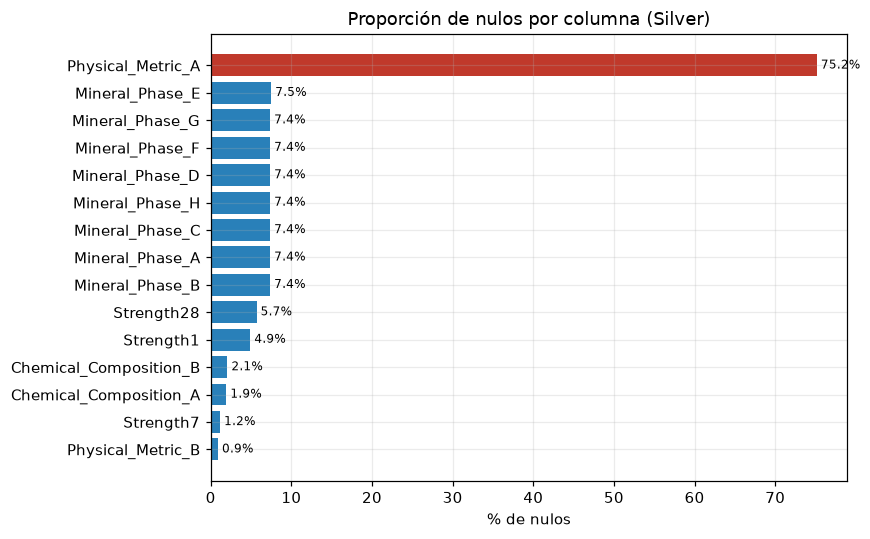

Nota: las fases minerales faltan EN BLOQUE (mismas filas), señal de que no se midieron en esos lotes, no de ruido aleatorio.


In [8]:
nulls = (silver[FEATURES + TARGETS].isna().mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(nulls.index, nulls.values, color=["#c0392b" if v > 20 else "#2980b9" for v in nulls.values])
ax.set_xlabel("% de nulos"); ax.set_title("Proporción de nulos por columna (Silver)")
for i, v in enumerate(nulls.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()
print("Nota: las fases minerales faltan EN BLOQUE (mismas filas), señal de que no se midieron en esos lotes, no de ruido aleatorio.")

### 3.3 Distribuciones

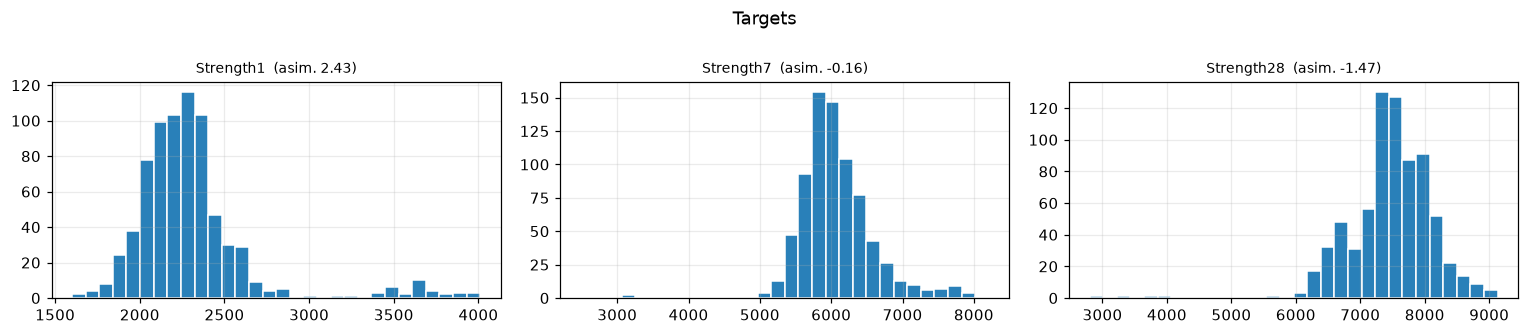

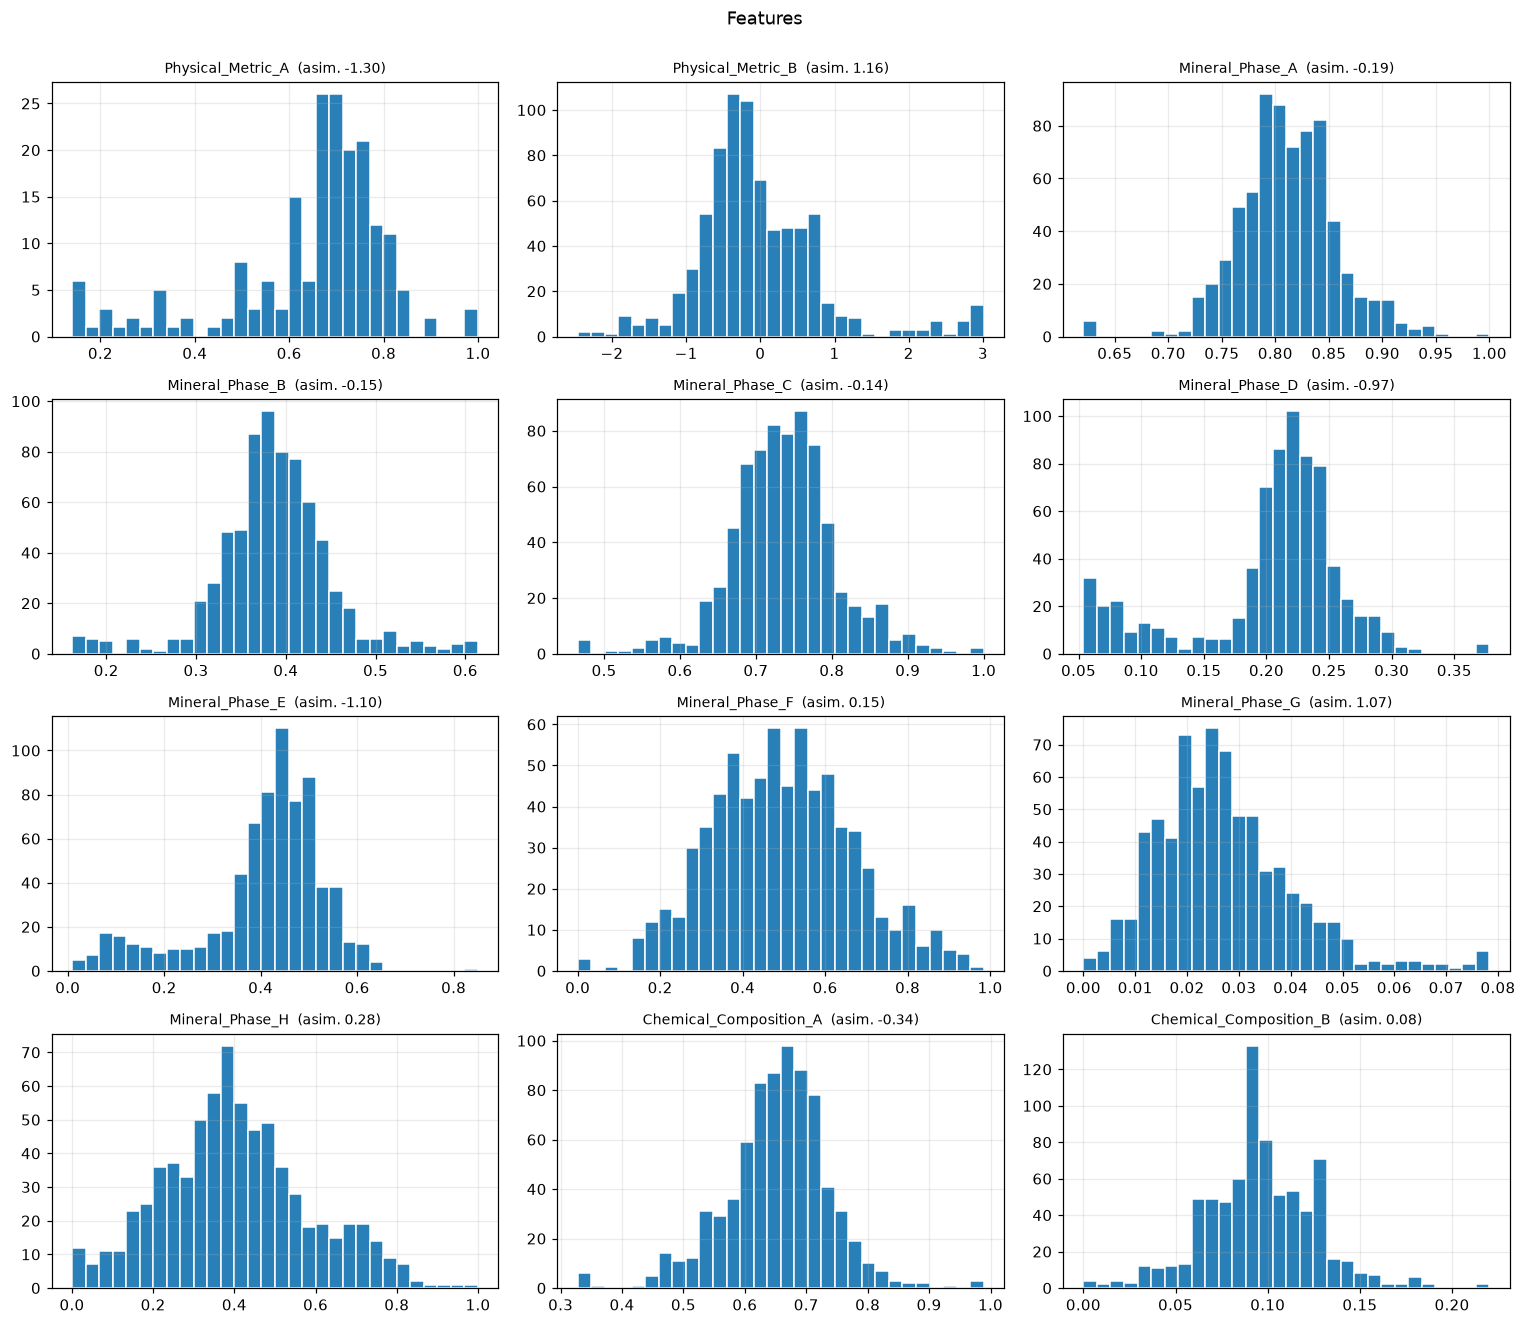

In [9]:
def hist_grid(cols, ncols=3, title=""):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        ax.hist(silver[c].dropna(), bins=30, color="#2980b9", edgecolor="white")
        ax.set_title(f"{c}  (asim. {silver[c].skew():.2f})", fontsize=9)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

hist_grid(TARGETS, title="Targets")
hist_grid(FEATURES, title="Features")

### 3.4 Boxplots por `ProductType`

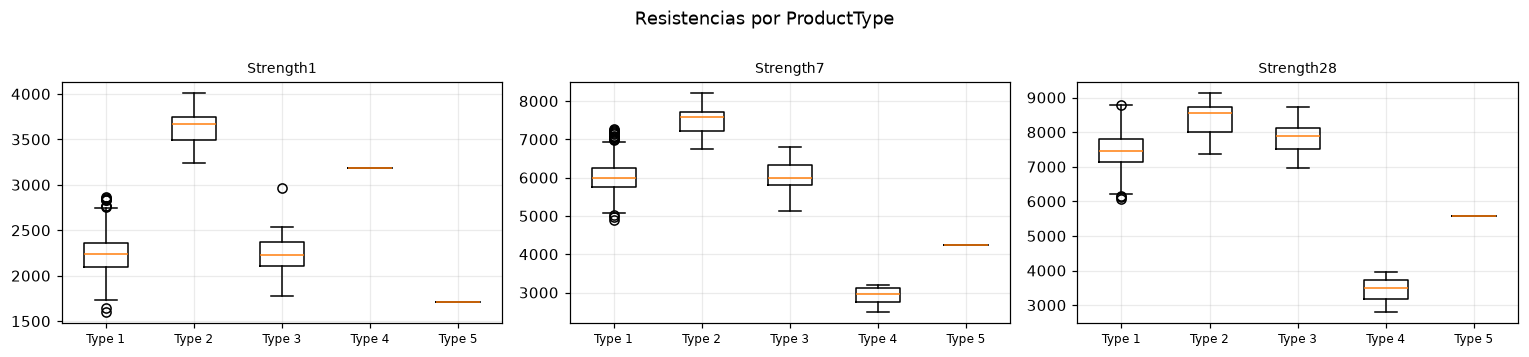

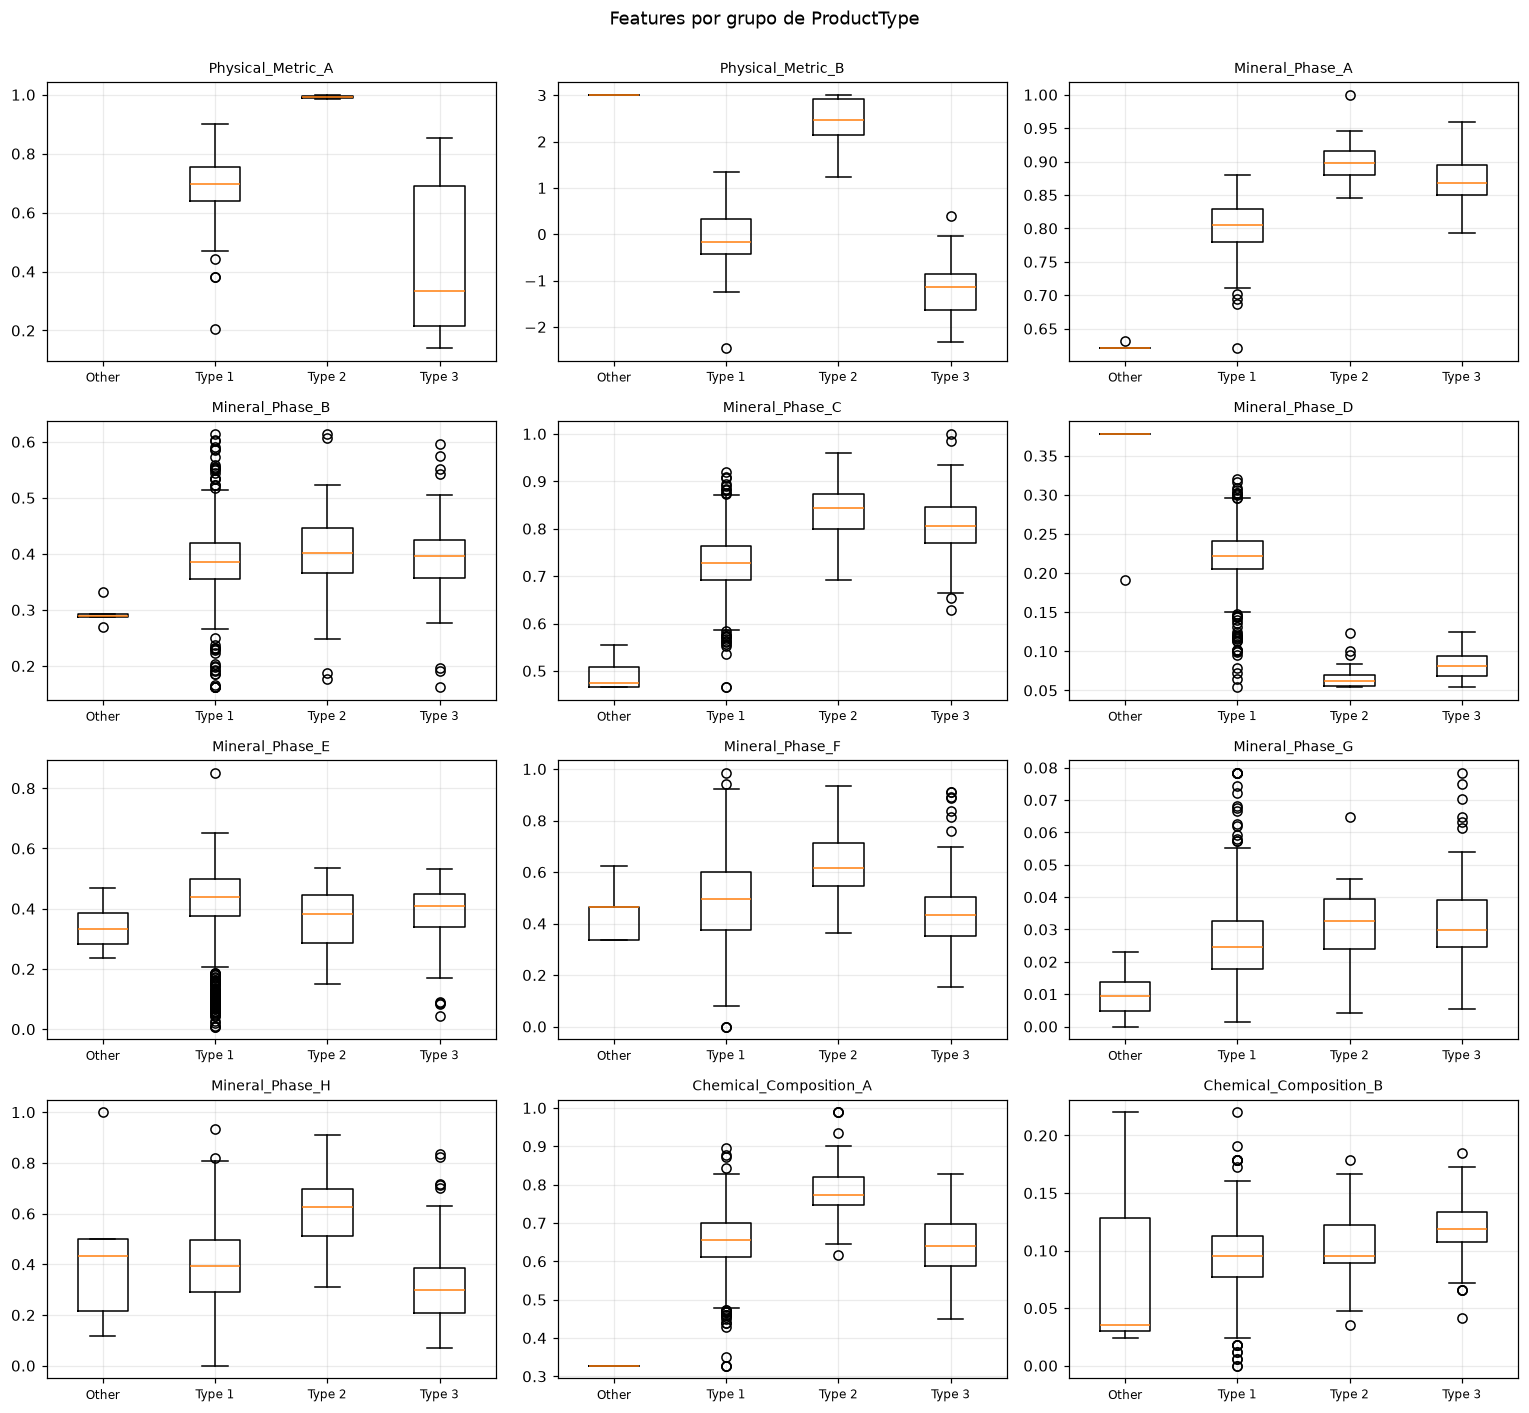

In [10]:
def box_by(cols, by, order, ncols=3, title=""):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.2 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        data = [silver.loc[silver[by] == g, c].dropna().values for g in order]
        ax.boxplot(data, showfliers=True)
        ax.set_xticks(range(1, len(order) + 1)); ax.set_xticklabels(order, fontsize=8)
        ax.set_title(c, fontsize=9)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis("off")
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

box_by(TARGETS, CAT, TYPES, title="Resistencias por ProductType")
box_by(FEATURES, "ProductType_group", GROUPS, title="Features por grupo de ProductType")

### 3.5 Outliers (IQR y Z-score)
Calculados **antes** del recorte de Silver para ver cuánto se movió cada variable.

In [11]:
rows = []
for c in FEATURES + TARGETS:
    x = pre_clip[c].dropna()
    q1, q3 = x.quantile([0.25, 0.75]); iqr = q3 - q1
    rows.append({
        "variable": c, "n": len(x),
        "IQR 1.5": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
        "IQR 3.0": int(((x < q1 - 3.0 * iqr) | (x > q3 + 3.0 * iqr)).sum()),
        "|Z| > 3": int((((x - x.mean()) / x.std()).abs() > 3).sum()),
        "máx |Z|": float(((x - x.mean()) / x.std()).abs().max()),
    })
out_tbl = pd.DataFrame(rows).set_index("variable")
display(out_tbl)

# ¿los outliers de resistencia son errores o son otro producto?
t1 = pre_clip.groupby(CAT)[TARGETS].median().round(0)
print("Mediana de resistencia por ProductType (si un 'outlier' coincide con un tipo, es un producto distinto, no un error):")
display(t1)

,n,IQR 1.5,IQR 3.0,|Z| > 3,máx |Z|
variable,,,,,
Physical_Metric_A,192,23,4,2,3.6653
Physical_Metric_B,766,49,12,12,8.6193
Mineral_Phase_A,716,18,5,7,14.0948
Mineral_Phase_B,716,52,8,10,8.4067
Mineral_Phase_C,716,35,4,7,9.6510
Mineral_Phase_D,716,118,20,4,9.7431
Mineral_Phase_E,715,75,3,4,4.5244
Mineral_Phase_F,716,4,0,0,2.9331
Mineral_Phase_G,716,23,5,1,25.1386


Mediana de resistencia por ProductType (si un 'outlier' coincide con un tipo, es un producto distinto, no un error):


,Strength1,Strength7,Strength28
ProductType,,,
Type 1,"2,240.0000","5,980.0000","7,465.0000"
Type 2,"3,670.0000","7,575.0000","8,540.0000"
Type 3,"2,230.0000","5,990.0000","7,900.0000"
Type 4,"3,190.0000","2,955.0000","3,485.0000"
Type 5,"1,710.0000","4,240.0000","5,580.0000"


### 3.6 Correlaciones

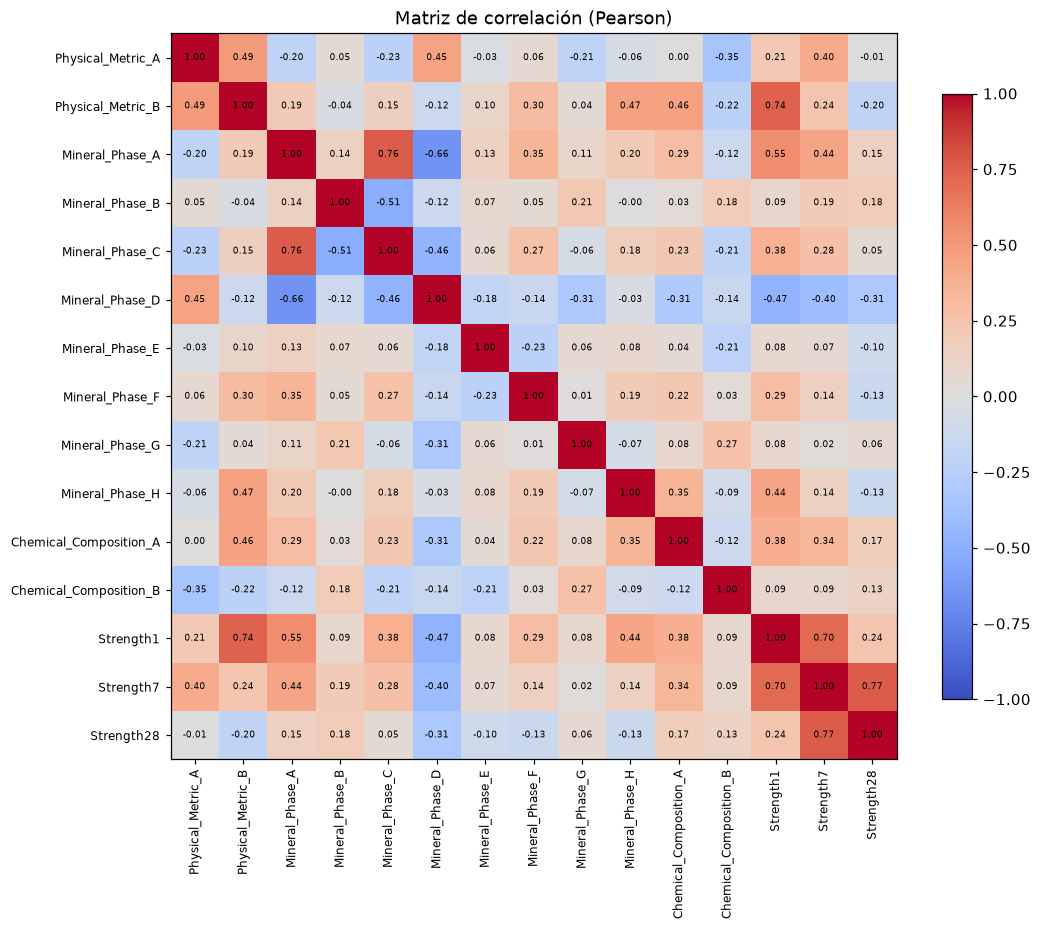

Pearson  (features vs targets)


,Strength1,Strength7,Strength28
Physical_Metric_A,0.2072,0.4039,-0.0083
Physical_Metric_B,0.7373,0.2402,-0.2005
Mineral_Phase_A,0.5516,0.4405,0.1451
Mineral_Phase_B,0.0884,0.1925,0.1814
Mineral_Phase_C,0.3814,0.2774,0.0483
Mineral_Phase_D,-0.4691,-0.4030,-0.3133
Mineral_Phase_E,0.0756,0.0651,-0.1049
Mineral_Phase_F,0.2892,0.1434,-0.1303
Mineral_Phase_G,0.0816,0.0178,0.0639
Mineral_Phase_H,0.4370,0.1355,-0.1307


Spearman (robusto a outliers)


,Strength1,Strength7,Strength28
Physical_Metric_A,0.1284,0.3541,0.0170
Physical_Metric_B,0.5372,0.0938,-0.2776
Mineral_Phase_A,0.5174,0.1910,-0.0993
Mineral_Phase_B,0.1488,0.1687,0.1227
Mineral_Phase_C,0.3588,0.0819,-0.1463
Mineral_Phase_D,-0.3367,-0.1702,-0.0608
Mineral_Phase_E,0.1033,0.0577,-0.1693
Mineral_Phase_F,0.2941,0.0912,-0.1646
Mineral_Phase_G,0.0407,-0.1150,-0.0225
Mineral_Phase_H,0.4869,0.0707,-0.1455


In [12]:
cols = FEATURES + TARGETS
corr = silver[cols].corr()
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm"); ax.grid(False)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=90, fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, shrink=0.8); ax.set_title("Matriz de correlación (Pearson)")
plt.tight_layout(); plt.show()

pear = corr.loc[FEATURES, TARGETS]
spear = silver[cols].corr(method="spearman").loc[FEATURES, TARGETS]
print("Pearson  (features vs targets)"); display(pear)
print("Spearman (robusto a outliers)");  display(spear)

### 3.7 Relación entre las 3 resistencias

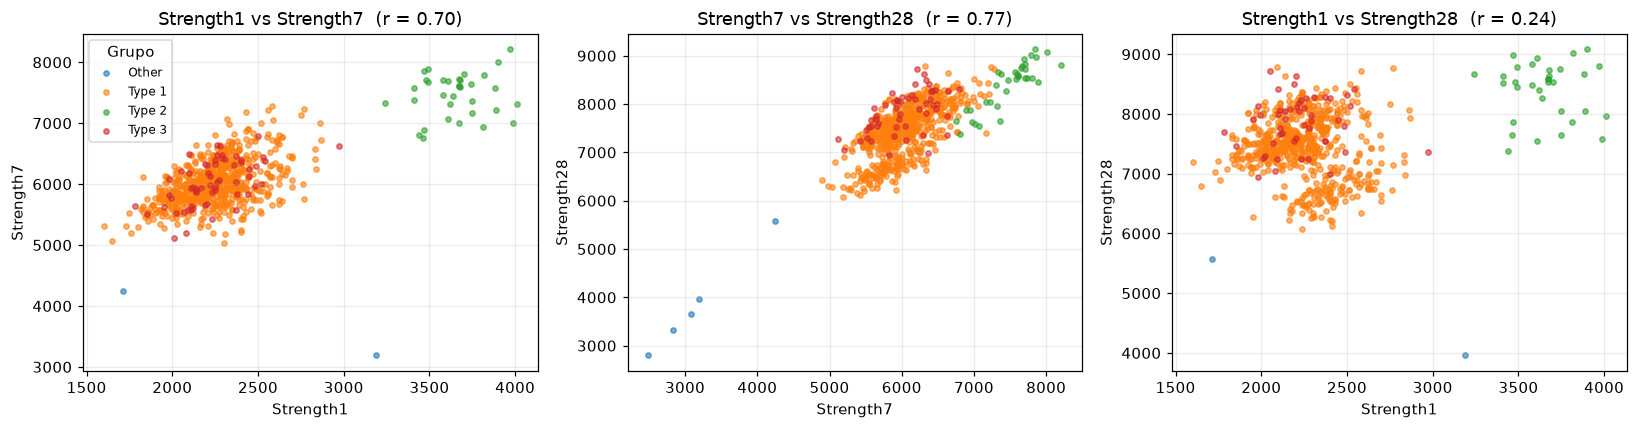

In [13]:
pairs = [("Strength1", "Strength7"), ("Strength7", "Strength28"), ("Strength1", "Strength28")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (a, b) in zip(axes, pairs):
    for g in GROUPS:
        d = silver[silver["ProductType_group"] == g]
        ax.scatter(d[a], d[b], s=12, alpha=0.6, color=palette[g], label=g)
    r = silver[[a, b]].corr().iloc[0, 1]
    ax.set_xlabel(a); ax.set_ylabel(b); ax.set_title(f"{a} vs {b}  (r = {r:.2f})")
axes[0].legend(fontsize=8, title="Grupo"); plt.tight_layout(); plt.show()

### 3.8 Scatter: las 3 features más correlacionadas (Spearman) con cada resistencia

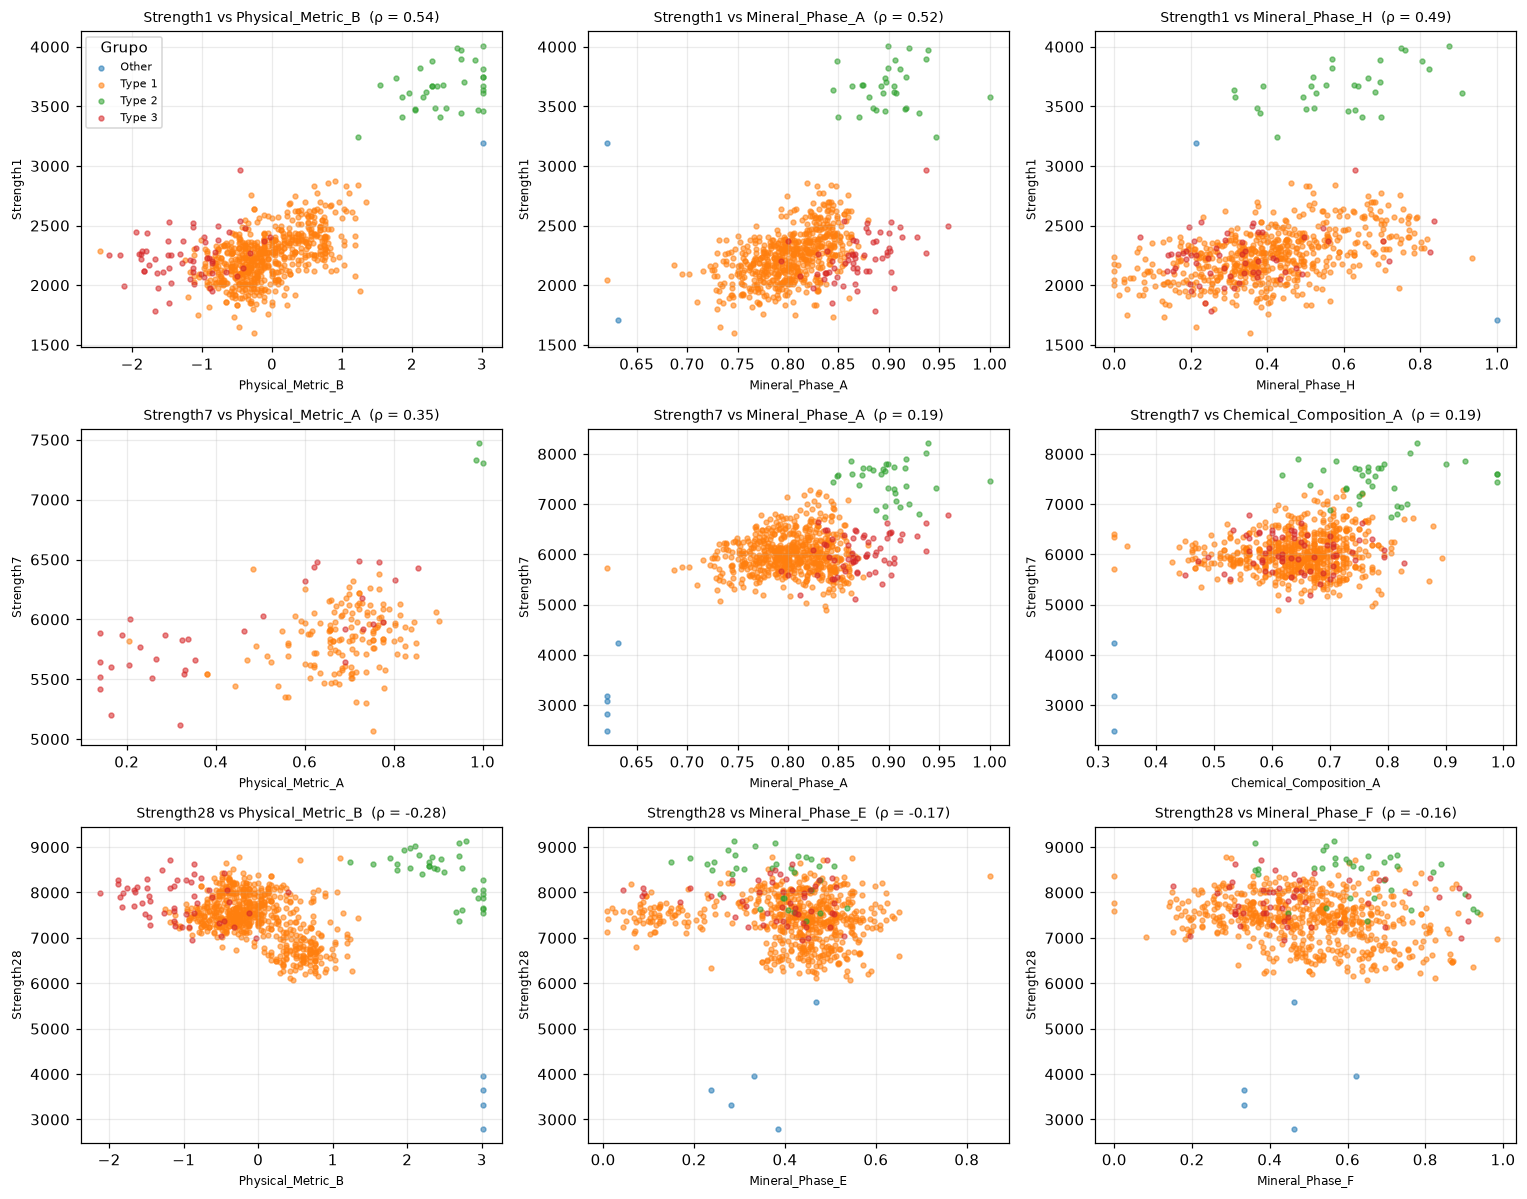

{'Strength1': ['Physical_Metric_B', 'Mineral_Phase_A', 'Mineral_Phase_H'], 'Strength7': ['Physical_Metric_A', 'Mineral_Phase_A', 'Chemical_Composition_A'], 'Strength28': ['Physical_Metric_B', 'Mineral_Phase_E', 'Mineral_Phase_F']}


In [14]:
top = {t: spear[t].abs().sort_values(ascending=False).head(3).index.tolist() for t in TARGETS}
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for i, t in enumerate(TARGETS):
    for j, f in enumerate(top[t]):
        ax = axes[i, j]
        for g in GROUPS:
            d = silver[silver["ProductType_group"] == g]
            ax.scatter(d[f], d[t], s=10, alpha=0.55, color=palette[g], label=g)
        ax.set_xlabel(f, fontsize=8); ax.set_ylabel(t, fontsize=8)
        ax.set_title(f"{t} vs {f}  (ρ = {spear.loc[f, t]:.2f})", fontsize=9)
axes[0, 0].legend(fontsize=7, title="Grupo"); plt.tight_layout(); plt.show()
print({t: top[t] for t in TARGETS})

### 3.9 Análisis por `ProductType`

,filas,Strength1 media,Strength1 std,Strength7 media,Strength7 std,Strength28 media,Strength28 std
ProductType,,,,,,,
Type 1,668,"2,242.1160",203.7299,"6,019.6510",383.4562,"7,430.8333",520.1348
Type 2,36,"3,654.4118",185.1157,"7,463.3333",363.5775,"8,394.2857",495.5940
Type 3,64,"2,235.0820",194.6503,"6,027.8125",370.2014,"7,832.8302",431.5731
Type 4,4,"3,190.0000",NaN,"2,897.5000",310.6311,"3,432.5000",496.0763
Type 5,1,"1,710.0000",NaN,"4,240.0000",NaN,"5,580.0000",NaN


% de nulos por tipo (Physical_Metric_A y fases minerales):


,Physical_Metric_A,Mineral_Phase_A,Mineral_Phase_B,Mineral_Phase_C,Mineral_Phase_D,Mineral_Phase_E,Mineral_Phase_F,Mineral_Phase_G,Mineral_Phase_H
ProductType,,,,,,,,,
Type 1,76.8000,7.8000,7.8000,7.8000,7.8000,7.9000,7.8000,7.8000,7.8000
Type 2,91.7000,8.3000,8.3000,8.3000,8.3000,8.3000,8.3000,8.3000,8.3000
Type 3,46.9000,3.1000,3.1000,3.1000,3.1000,3.1000,3.1000,3.1000,3.1000
Type 4,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Type 5,100.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


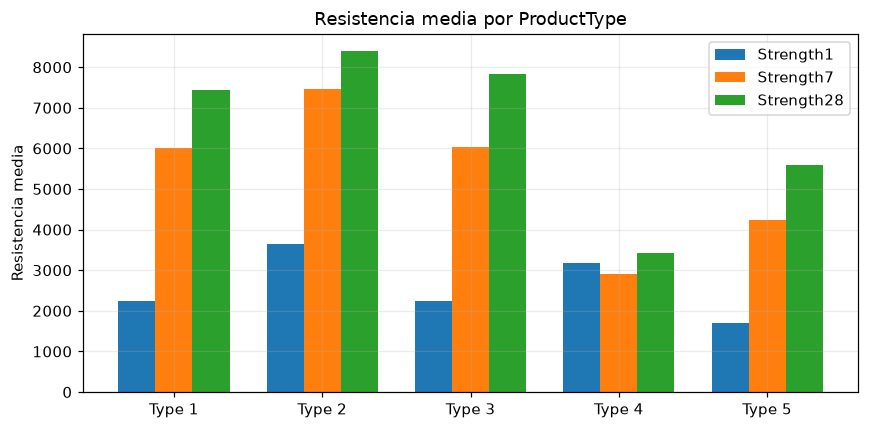

In [15]:
agg = {"filas": (TARGETS[0], "size")}
for t in TARGETS:
    agg[f"{t} media"] = (t, "mean")
    agg[f"{t} std"] = (t, "std")
by_type = silver.groupby(CAT).agg(**agg)
display(by_type)

print("% de nulos por tipo (Physical_Metric_A y fases minerales):")
display((silver[[PHYS_A] + MINERALS].isna().groupby(silver[CAT]).mean() * 100).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
w = 0.25
for k, t in enumerate(TARGETS):
    ax.bar(np.arange(len(by_type)) + k * w, by_type[f"{t} media"], w, label=t)
ax.set_xticks(np.arange(len(by_type)) + w); ax.set_xticklabels(by_type.index)
ax.set_ylabel("Resistencia media"); ax.set_title("Resistencia media por ProductType"); ax.legend()
plt.tight_layout(); plt.show()

### 3.10 Multicolinealidad (VIF)
Se calcula con filas completas y **sin** `Physical_Metric_A` (demasiados nulos). VIF = diagonal de la inversa de la matriz de correlación.

In [16]:
def vif_table(X):
    Z = (X - X.mean()) / X.std(ddof=0)
    inv = np.linalg.pinv(np.corrcoef(Z.values, rowvar=False))
    return pd.Series(np.diag(inv), index=X.columns, name="VIF").sort_values(ascending=False)

vif_cols = [c for c in FEATURES if c != PHYS_A]
Xcc = silver[vif_cols].dropna()
vif = vif_table(Xcc)
print(f"Filas completas usadas: {len(Xcc):,}")
display(vif.to_frame().assign(**{f"> {VIF_THRESHOLD}": lambda d: d["VIF"] > VIF_THRESHOLD}))

high = silver[FEATURES].corr().abs().where(lambda m: np.triu(np.ones(m.shape, bool), 1))
pairs_hi = high.stack().sort_values(ascending=False)
print("Pares de features con |r| > 0.7:"); display(pairs_hi[pairs_hi > 0.7].rename("|r|").to_frame())
print("Si algún VIF supera el umbral, agréguenlo a DROP_FEATURES (celda de configuración) y vuelvan a correr desde la sección 4.")

Filas completas usadas: 695


,VIF,> 10
Mineral_Phase_C,100.3540,True
Mineral_Phase_A,68.3444,True
Mineral_Phase_B,45.8992,True
Mineral_Phase_D,2.4769,False
Physical_Metric_B,1.7465,False
Chemical_Composition_A,1.5161,False
Mineral_Phase_H,1.4499,False
Mineral_Phase_F,1.4003,False
Chemical_Composition_B,1.3792,False
Mineral_Phase_E,1.2785,False


Pares de features con |r| > 0.7:


,,|r|
Mineral_Phase_A,Mineral_Phase_C,0.7634


Si algún VIF supera el umbral, agréguenlo a DROP_FEATURES (celda de configuración) y vuelvan a correr desde la sección 4.


In [17]:
# ¿Por qué el VIF de A, B y C es tan alto? Se revisa en el dato crudo, antes de winsorizar.
abc = raw[["Mineral_Phase_A", "Mineral_Phase_B", "Mineral_Phase_C"]].dropna()
A_mat = np.column_stack([abc["Mineral_Phase_B"], abc["Mineral_Phase_C"], np.ones(len(abc))])
coef, *_ = np.linalg.lstsq(A_mat, abc["Mineral_Phase_A"], rcond=None)
ajuste = A_mat @ coef
r2_abc = 1 - ((abc["Mineral_Phase_A"] - ajuste) ** 2).sum() / ((abc["Mineral_Phase_A"] - abc["Mineral_Phase_A"].mean()) ** 2).sum()
print(f"Crudo: Mineral_Phase_A = {coef[0]:.3f}·B + {coef[1]:.3f}·C + {coef[2]:.3f}  (R² = {r2_abc:.5f}, n = {len(abc)})")

sin_A = [c for c in vif_cols if c != "Mineral_Phase_A"]
print("VIF de Silver sin Mineral_Phase_A:")
display(vif_table(silver[sin_A].dropna()).head(4).to_frame())

Crudo: Mineral_Phase_A = 0.539·B + 0.818·C + -0.000  (R² = 1.00000, n = 720)
VIF de Silver sin Mineral_Phase_A:


,VIF
Mineral_Phase_C,3.4818
Mineral_Phase_B,2.4341
Mineral_Phase_D,2.4299
Physical_Metric_B,1.6554


### 3.11 Hallazgos (completen con el equipo)
Dejen aquí lo que encontraron: es lo que se defiende en el Q&A y alimenta el criterio de *entendimiento del problema*.

- **Calidad del dato:** nulos en bloque (¿qué mide cada bloque y por qué faltaría en el lote?), `Physical_Metric_A` casi vacía.
- **Producto:** desbalance fuerte entre `ProductType`; los tipos raros tienen resistencias muy distintas. ¿Son otro producto o error de captura?
- **Asimetría:** variables con colas pesadas (revisar tabla 3.1) y qué se hizo con ellas.
- **Relaciones:** qué variables mandan en cada edad (1, 7, 28 días). ¿Cambia el patrón? ¿Tiene sentido químicamente?
- **Targets:** S7 y S28 están muy correlacionadas; S1 menos. ¿Qué implica para modelarlas?
- **Multicolinealidad:** resultado del VIF y qué variables decidieron conservar.

## 4. Gold · features + targets listos para ML
- Split **estratificado por grupo de producto**, 80/20, con `random_state` fijo. Queda guardado en la columna `split` → **los 3 integrantes entrenan con exactamente el mismo train/test**.
- Imputación por **mediana del grupo calculada solo con el train** (fallback: mediana global del train).
- One-hot de `ProductType_group`, indicadores de faltante y separación clara de targets.
- **No se escala aquí:** el escalado va dentro del `Pipeline` del modelo que lo necesite (p. ej. `StandardScaler` + Ridge), ajustado solo con train. Los modelos de árboles no lo requieren.

In [18]:
silver = load_table(SILVER)
FEAT = [c for c in FEATURES if c not in DROP_FEATURES]
FLAGS = ["Physical_Metric_A_missing", "Mineral_Phases_missing"]
print("Features usadas:", len(FEAT), "| descartadas:", DROP_FEATURES or "ninguna")

g = silver.copy()

# --- split estratificado ---
try:
    idx_tr, idx_te = train_test_split(g.index, test_size=TEST_SIZE, random_state=RANDOM_STATE,
                                      stratify=g["ProductType_group"])
except ValueError as e:
    print("Estratificación no posible, split simple:", e)
    idx_tr, idx_te = train_test_split(g.index, test_size=TEST_SIZE, random_state=RANDOM_STATE)
g["split"] = np.where(g.index.isin(idx_tr), "train", "test")

# --- imputación con estadísticos del train ---
train = g[g["split"] == "train"]
med_group = train.groupby("ProductType_group")[FEAT].median()
med_global = train[FEAT].median()
for c in FEAT:
    g[c] = g[c].fillna(g["ProductType_group"].map(med_group[c])).fillna(med_global[c])

# --- feature engineering: agreguen aquí lo que se les ocurra (con base en el EDA) ---
# g["Phys_B_x_PhaseD"] = g["Physical_Metric_B"] * g["Mineral_Phase_D"]
ENGINEERED = []

# --- one-hot del grupo de producto ---
dummies = pd.get_dummies(g["ProductType_group"], prefix="ProductType", dtype=int)
dummies.columns = [c.replace(" ", "_") for c in dummies.columns]

gold = pd.concat([g[["row_id", CAT, "ProductType_group", "split"]],
                  g[FEAT + FLAGS + ENGINEERED], dummies, g[TARGETS]], axis=1)

# --- chequeos ---
FEATURE_COLS = FEAT + FLAGS + ENGINEERED + list(dummies.columns)
assert not gold[FEATURE_COLS].isna().any().any(), "Quedaron nulos en X"
assert not set(TARGETS) & set(FEATURE_COLS), "Un target está en X"
assert gold["row_id"].is_unique
save_table(gold, GOLD)

print(f"\nX: {len(FEATURE_COLS)} columnas")
display(gold["split"].value_counts().rename("filas").to_frame())
display(pd.crosstab(gold["ProductType_group"], gold["split"]))

Features usadas: 12 | descartadas: ninguna
✔ guardada datathon.gold.datathon_data_gold  (773 filas × 25 cols)

X: 18 columnas


,filas
split,
train,618
test,155


split,test,train
ProductType_group,,
Other,1,4
Type 1,134,534
Type 2,7,29
Type 3,13,51


### 4.1 Contrato para el notebook de ML
`get_xy` entrega X/y de cada target con el split compartido; el benchmark de la sección 5 la usa directamente.

In [19]:
def get_xy(gold_df, target):
    """Devuelve X_train, y_train, X_test, y_test para un target (solo filas donde ese target existe)."""
    d = gold_df[gold_df[target].notna()]
    feats = [c for c in gold_df.columns
             if c not in TARGETS + ["row_id", "split", "ProductType", "ProductType_group"]]
    tr, te = d[d["split"] == "train"], d[d["split"] == "test"]
    return tr[feats], tr[target], te[feats], te[target]

gold_loaded = load_table(GOLD)
resumen = []
for t in TARGETS:
    Xtr, ytr, Xte, yte = get_xy(gold_loaded, t)
    resumen.append({"target": t, "n_features": Xtr.shape[1], "train_size": len(Xtr), "test_size": len(Xte)})
display(pd.DataFrame(resumen))   # estos valores van directo a los params de MLflow

,target,n_features,train_size,test_size
0,Strength1,18,589,146
1,Strength7,18,610,154
2,Strength28,18,582,147


### 4.2 Resumen del pipeline

In [20]:
resumen_capas = pd.DataFrame([
    {"capa": "Bronze", "tabla": BRONZE, "filas": len(bronze), "columnas": bronze.shape[1]},
    {"capa": "Silver", "tabla": SILVER, "filas": len(silver), "columnas": silver.shape[1]},
    {"capa": "Gold",   "tabla": GOLD,   "filas": len(gold),   "columnas": gold.shape[1]},
])
display(resumen_capas)
print(f"Filas eliminadas Bronze -> Silver: {len(bronze) - len(silver)}")

,capa,tabla,filas,columnas
0,Bronze,datathon.bronze.datathon_data_bronze,791,19
1,Silver,datathon.silver.datathon_data_silver,773,20
2,Gold,datathon.gold.datathon_data_gold,773,25


Filas eliminadas Bronze -> Silver: 18


## 5. Benchmark de modelos
Mismos 3 algoritmos y métricas de `sample.ipynb`, ahora alimentados por la capa Gold. Estos son los cambios respecto a ese benchmark:

| Tema | `sample.ipynb` | Aquí | Motivo |
|---|---|---|---|
| Limpieza | Enmascara outliers como `NaN` (778 filas) | Silver: winsoriza y valida (773 filas) | Es el pipeline documentado del equipo |
| Split | Uno por target, `random_state=18` | Columna `split` de Gold, `random_state=42` | Todos evalúan con las mismas filas |
| Nulos | Mediana global o `NaN` nativo en árboles | Mediana por grupo de Gold + indicadores de faltante | Se calcula solo con train |
| `ProductType` | Dummies de Type 2 a Type 5 | Dummies de grupo; Type 4 y 5 quedan en `Other` | Solo quedan 5 filas de esos tipos en Silver |
| Selección | Se comparan métricas de test | CV anidada en train; test solo para reportar | Elegir con test infla la métrica reportada |

Las métricas son `R2`, `MAE`, `MAPE` y `R2_within_Type1`. Esta última importa porque `R2` global se alimenta de la diferencia *entre* tipos de producto, mientras que `R2_within_Type1` mide si el modelo explica la variación *dentro* del producto principal (86% de las filas).

### 5.1 Datos y features candidatas
Combinaciones fila a fila (no se ajusta nada, así que son seguras para datos nuevos). Solo se usan columnas con más de 50% de valores medidos, lo que excluye a `Physical_Metric_A`.

In [21]:
import itertools
import time
from dataclasses import dataclass
from typing import Callable

from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

np.random.seed(RANDOM_STATE)
cv = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

gold_df = load_table(GOLD)
assert (gold_df["row_id"].values == silver["row_id"].values).all(), "Silver y Gold deben estar alineadas"

USABLE = [f for f in FEAT if silver[f].notna().mean() > 0.5]
# log/sqrt/inv y división solo tienen sentido en escalas no negativas. Physical_Metric_B viene
# estandarizada (cruza el cero): solo recibe x y cuadrado, y nunca va como denominador.
NONNEG = [f for f in USABLE if silver[f].min() >= 0]
EPS = 1e-3
UNARY = {
    "x": lambda s: s,
    "log": lambda s: np.log(s + EPS),
    "sqrt": lambda s: np.sqrt(s),
    "square": lambda s: s ** 2,
    "inv": lambda s: 1 / (s + EPS),
}
SIGNED_SAFE = {"x", "square"}

# Type 1 es la referencia del modelo lineal. Solo Type 2 y Type 3 tienen filas para pendiente propia.
TYPE_COLS = [c for c in FEATURE_COLS if c.startswith("ProductType_") and c != "ProductType_Type_1"]
SLOPE_TYPES = ["ProductType_Type_2", "ProductType_Type_3"]


def build_candidates(frame):
    candidates = {}
    for f in USABLE:
        for name, fn in UNARY.items():
            if f in NONNEG or name in SIGNED_SAFE:
                candidates[f"{name}({f})"] = fn(frame[f])
    for a, b in itertools.combinations(USABLE, 2):
        candidates[f"{a}*{b}"] = frame[a] * frame[b]
        candidates[f"{a}+{b}"] = frame[a] + frame[b]
        candidates[f"{a}-{b}"] = frame[a] - frame[b]
        if b in NONNEG:
            candidates[f"{a}/{b}"] = frame[a] / (frame[b] + EPS)
        if a in NONNEG:
            candidates[f"{b}/{a}"] = frame[b] / (frame[a] + EPS)
    return pd.DataFrame(candidates, index=frame.index).replace([np.inf, -np.inf], np.nan)


def build_model_features(frame):
    """Candidatas + indicadores de faltante + dummies de grupo + interacciones candidata × tipo."""
    cands = build_candidates(frame)
    inter = {f"{c}:{t}": cands[c] * frame[t] for c in cands for t in SLOPE_TYPES}
    return pd.concat([cands, frame[FLAGS + TYPE_COLS], pd.DataFrame(inter, index=frame.index)], axis=1)


X_cand = build_candidates(gold_df)
X_all = build_model_features(gold_df)
X_tree = gold_df[FEATURE_COLS]   # los árboles encuentran no linealidades y cortes por tipo por sí solos
print(f"{X_cand.shape[1]} candidatas | {X_all.shape[1]} columnas para el lineal | {X_tree.shape[1]} para árboles")

317 candidatas | 956 columnas para el lineal | 18 para árboles


### 5.2 Mejores predictores individuales
Para cada target, las candidatas que mejor linealizan la resistencia. Se calcula **solo con train**.

In [22]:
best_single = {}
for target in TARGETS:
    Xtr, ytr, _, _ = get_xy(gold_df, target)
    abs_r = X_cand.loc[ytr.index].corrwith(ytr).abs().sort_values(ascending=False)
    rows = []
    for name in abs_r.head(5).index:
        r2 = cross_val_score(LinearRegression(), X_cand.loc[ytr.index, [name]], ytr, cv=cv, scoring="r2").mean()
        rows.append({"predictor": name, "abs_r": abs_r[name], "cv_r2": r2})
    ranking = pd.DataFrame(rows).sort_values("cv_r2", ascending=False)
    best_single[target] = ranking.iloc[0]["predictor"]
    print(target)
    display(ranking.round(3))

Strength1


,predictor,abs_r,cv_r2
0,Physical_Metric_B*Chemical_Composition_A,0.7780,0.5920
3,Physical_Metric_B*Mineral_Phase_H,0.7540,0.5630
4,Physical_Metric_B-Mineral_Phase_D,0.7470,0.5550
1,Mineral_Phase_H/Mineral_Phase_D,0.7650,0.5530
2,Physical_Metric_B/Mineral_Phase_D,0.7620,0.5530


Strength7


,predictor,abs_r,cv_r2
0,Mineral_Phase_D/Chemical_Composition_A,0.4990,0.2260
1,Mineral_Phase_A+Chemical_Composition_A,0.4840,0.2130
4,Chemical_Composition_A/Mineral_Phase_D,0.4670,0.2100
2,Mineral_Phase_D-Chemical_Composition_A,0.4810,0.2090
3,Mineral_Phase_B+Mineral_Phase_C,0.4700,0.2060


Strength28


,predictor,abs_r,cv_r2
0,Physical_Metric_B*Mineral_Phase_D,0.4710,0.1740
1,Mineral_Phase_D/Chemical_Composition_A,0.3970,0.1180
4,Mineral_Phase_B/Mineral_Phase_D,0.3340,0.0990
3,Mineral_Phase_D*Mineral_Phase_F,0.3390,0.0950
2,Mineral_Phase_D/Mineral_Phase_B,0.3410,0.0730


### 5.3 Modelo lineal: ¿cuánto aporta cada bloque?
El lineal usa selección *forward* sobre las candidatas. Las tres configuraciones separan lo que aporta conocer el tipo de producto de lo que aportan las variables de calidad. Solo `combinations + type` pasa al benchmark.

In [23]:
LINEAR = "linear (combinations + type)"


def make_model():
    # Imputador y escalado viven en el pipeline: se ajustan solo con las filas de entrenamiento.
    # El imputador es una red de seguridad para candidatas no definidas en datos nuevos.
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         RidgeCV(alphas=np.logspace(-3, 3, 13)))


def forward_select(X, y, pool, forced=(), max_features=8, min_gain=0.005):
    """Parte de las columnas forzadas y agrega la candidata que más mejora el R2 de CV."""
    def cv_r2(cols):
        return cross_val_score(make_model(), X[cols], y, cv=cv, scoring="r2").mean()

    chosen = list(forced)
    best = cv_r2(chosen) if chosen else -np.inf
    while len(chosen) - len(forced) < max_features:
        scores = {c: cv_r2(chosen + [c]) for c in pool if c not in chosen}
        c, s = max(scores.items(), key=lambda kv: kv[1])
        if s - best < min_gain:
            break
        chosen.append(c)
        best = s
    return chosen


def top_candidates(idx, y):
    return X_cand.loc[idx].corrwith(y).abs().sort_values(ascending=False).index


def select_linear_cols(idx, y):
    top = top_candidates(idx, y)
    pool = list(top[:40]) + [f"{c}:{t}" for c in top[:10] for t in SLOPE_TYPES] + FLAGS
    return forward_select(X_all.loc[idx], y, pool, forced=TYPE_COLS)


def metric_row(y_true, y_pred):
    type1 = gold_df.loc[y_true.index, CAT] == "Type 1"
    return {"R2": r2_score(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE": mean_absolute_percentage_error(y_true, y_pred),
            "R2_within_Type1": r2_score(y_true[type1], y_pred[type1])}


start = time.perf_counter()
linear_cols, linear_rows = {}, []
with threadpool_limits(limits=N_THREADS):
    for target in TARGETS:
        Xtr, ytr, Xte, yte = get_xy(gold_df, target)
        tr, te = ytr.index, yte.index
        linear_cols[target] = select_linear_cols(tr, ytr)
        configs = {
            "type mean only": TYPE_COLS,
            "combinations only": forward_select(X_all.loc[tr], ytr, list(top_candidates(tr, ytr)[:40])),
            "combinations + type": linear_cols[target],
        }
        for label, cols in configs.items():
            model = make_model().fit(X_all.loc[tr, cols], ytr)
            pred = pd.Series(model.predict(X_all.loc[te, cols]), index=te)
            linear_rows.append({"target": target, "config": label, "n_features": len(cols), **metric_row(yte, pred)})
        print(f"{target}: {[c for c in linear_cols[target] if c not in TYPE_COLS]}")

display(pd.DataFrame(linear_rows).round(3))
print(f"Tiempo: {time.perf_counter() - start:.0f} s")

Strength1: ['Physical_Metric_B/Mineral_Phase_C', 'Physical_Metric_B/Chemical_Composition_A', 'Physical_Metric_B*Mineral_Phase_B', 'Physical_Metric_B-Mineral_Phase_H', 'Chemical_Composition_A/Mineral_Phase_D', 'Physical_Metric_B*Chemical_Composition_B', 'Physical_Metric_B*Mineral_Phase_E']


Strength7: ['Physical_Metric_A_missing', 'Mineral_Phase_A+Chemical_Composition_B', 'Physical_Metric_B/Mineral_Phase_D', 'Mineral_Phase_A+Mineral_Phase_G', 'Mineral_Phase_A-Mineral_Phase_G', 'Mineral_Phase_D/Mineral_Phase_B']


Strength28: ['Physical_Metric_B/Mineral_Phase_C', 'Physical_Metric_A_missing', 'Mineral_Phase_F-Chemical_Composition_A', 'Mineral_Phase_B*Chemical_Composition_A', 'Mineral_Phase_A-Mineral_Phase_D', 'sqrt(Mineral_Phase_D)']


,target,config,n_features,R2,MAE,MAPE,R2_within_Type1
0,Strength1,type mean only,3,0.5970,165.9150,0.0750,-0.0080
1,Strength1,combinations only,4,0.7040,138.1560,0.0620,0.2700
2,Strength1,combinations + type,10,0.7180,137.1430,0.0620,0.3070
3,Strength7,type mean only,3,0.5460,277.7150,0.0460,-0.0080
4,Strength7,combinations only,8,0.4290,316.5650,0.0530,-0.1070
5,Strength7,combinations + type,9,0.5880,272.9060,0.0460,0.1110
6,Strength28,type mean only,3,0.3790,421.3670,0.0580,-0.0020
7,Strength28,combinations only,5,0.4720,391.6820,0.0530,0.1640
8,Strength28,combinations + type,9,0.5770,352.8200,0.0480,0.3300


Tiempo: 38 s


#### Predictores elegidos, por grupo de producto
Se grafican los valores medidos de Silver, sin los imputados de Gold. Se traza tendencia solo en grupos con suficientes filas.

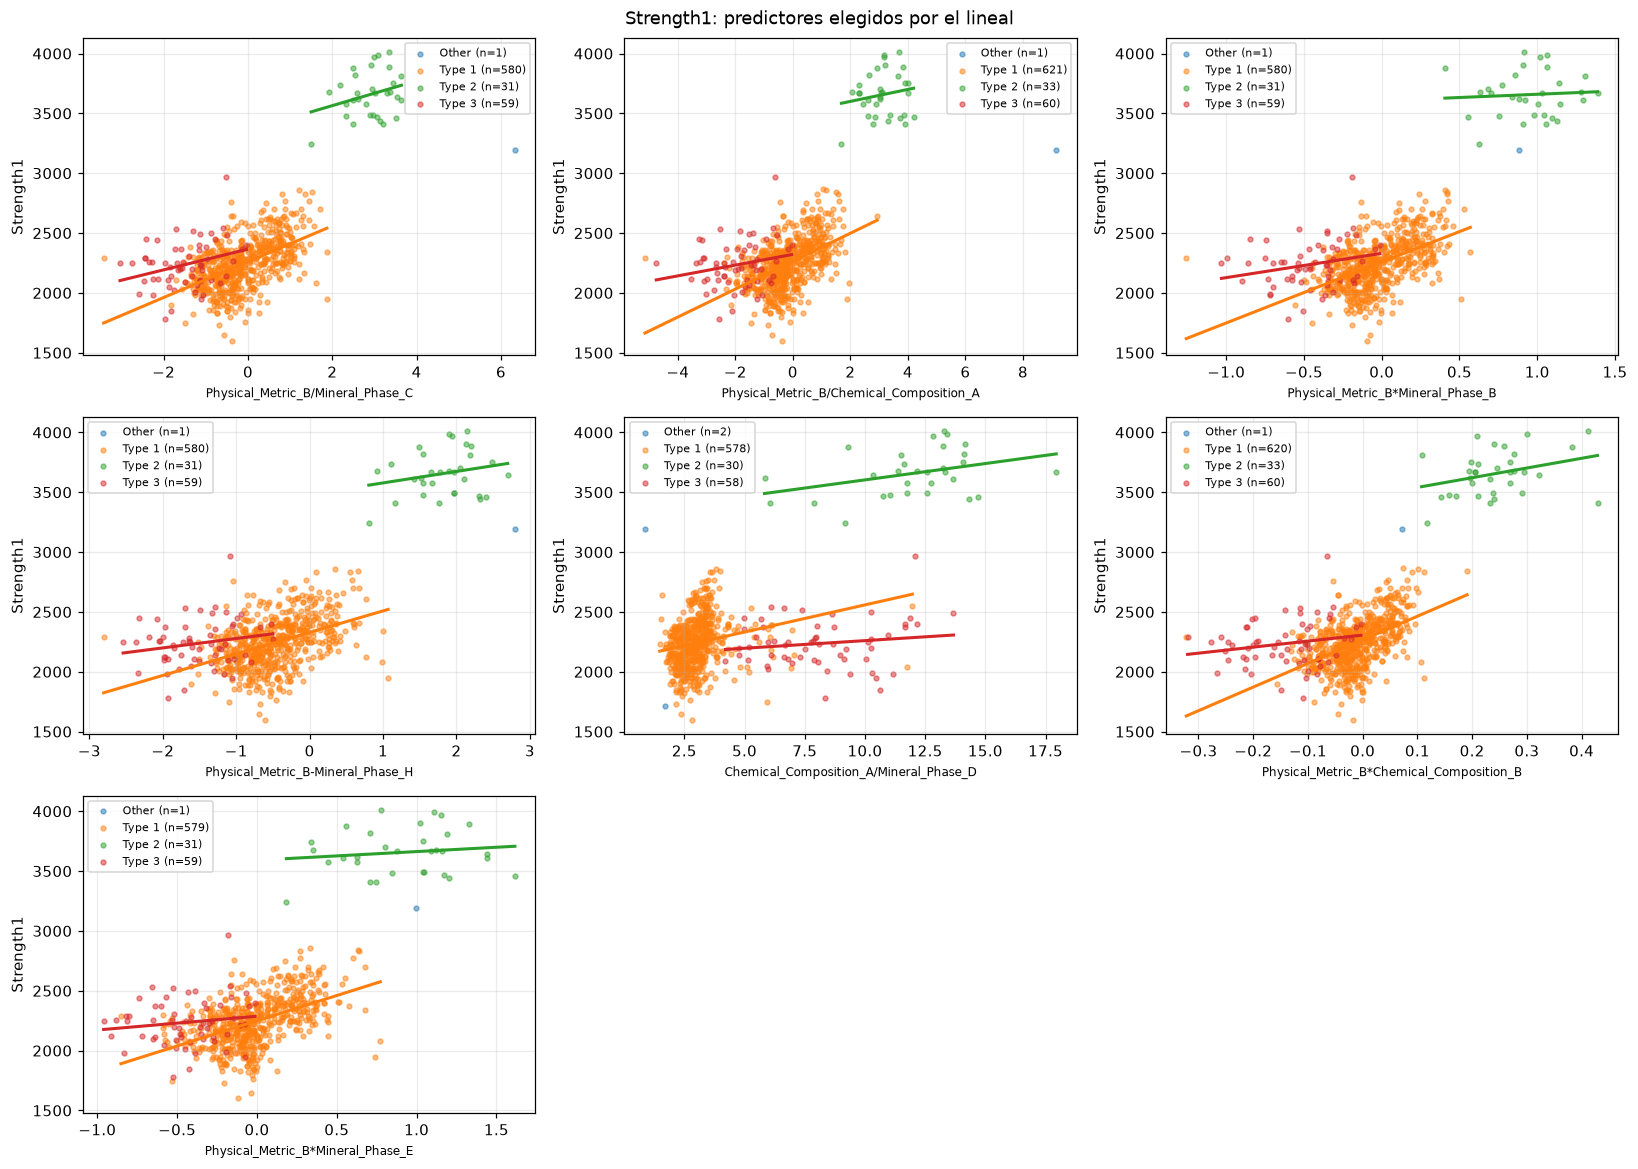

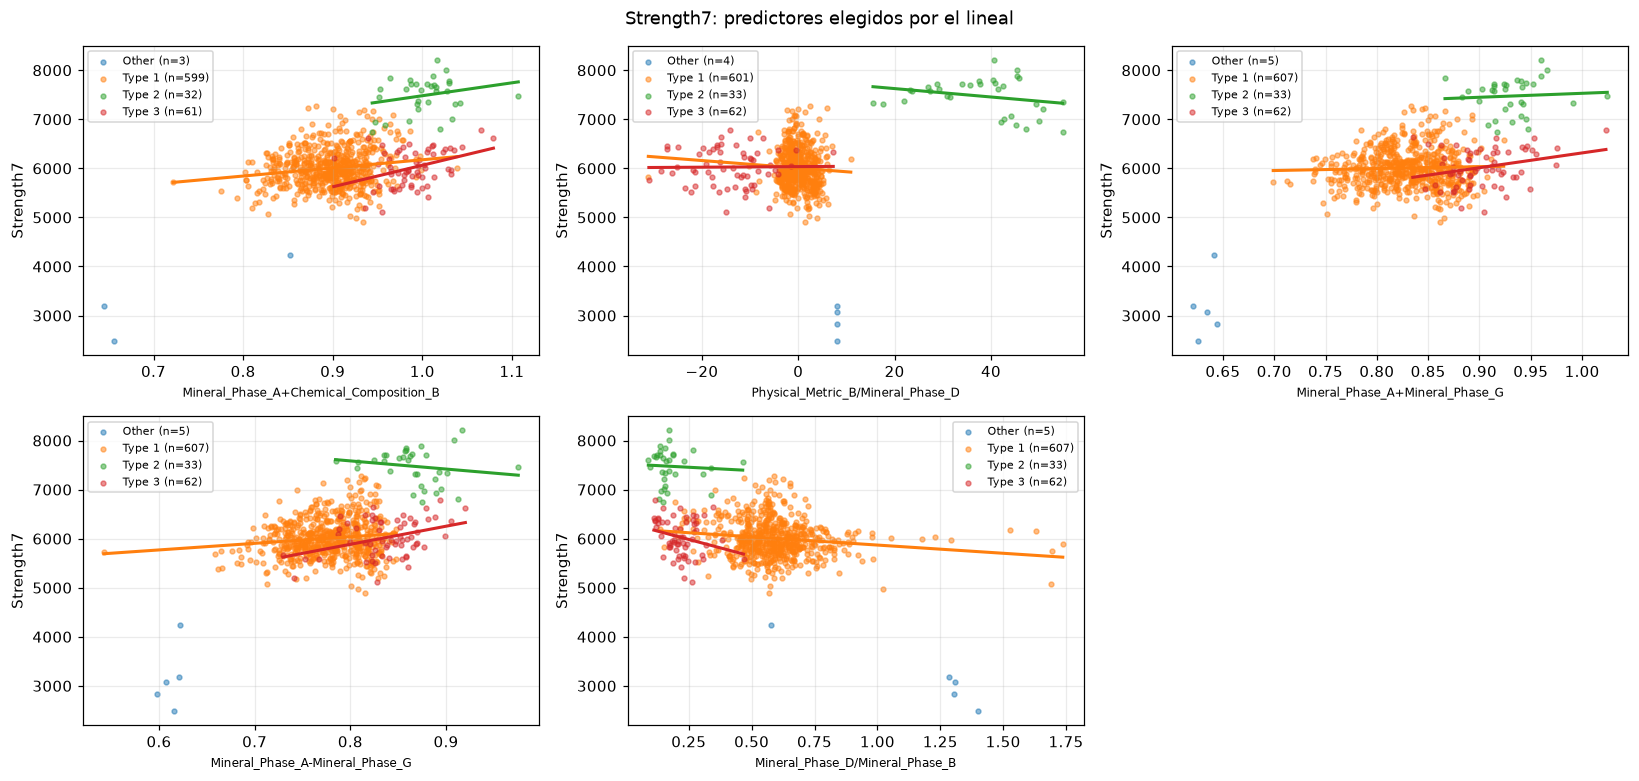

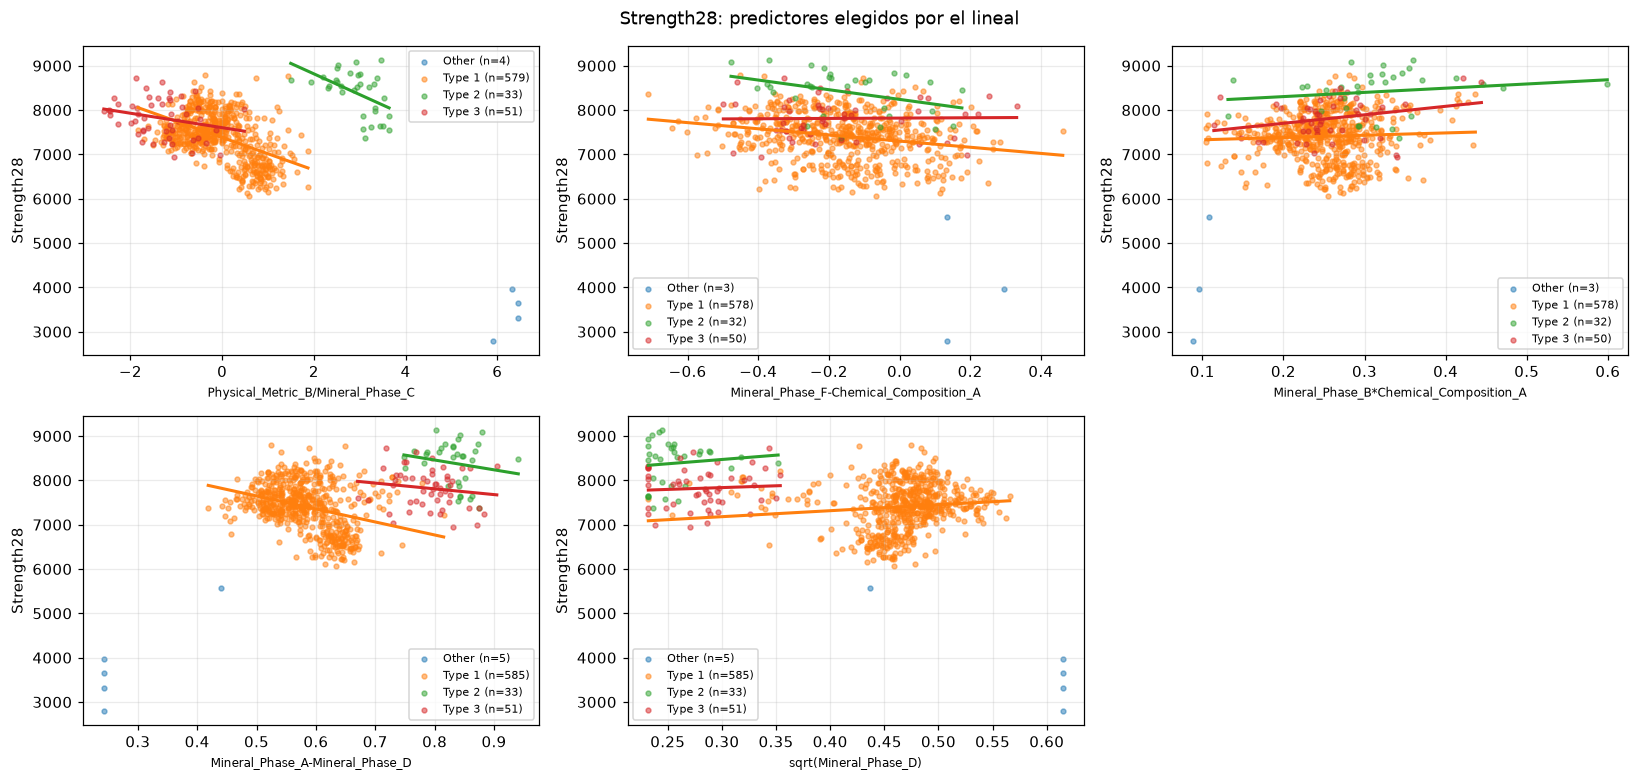

In [24]:
MIN_ROWS_FOR_FIT = 10
X_measured = build_candidates(silver)

for target in TARGETS:
    # Una interacción ("c:ProductType_Type_2") es el mismo predictor con otra pendiente: se dibuja c una vez
    plot_cols = list(dict.fromkeys(c.split(":")[0] for c in linear_cols[target] if c not in TYPE_COLS + FLAGS))
    if not plot_cols:
        print(f"{target}: el lineal no eligió combinaciones")
        continue
    n_cols = min(3, len(plot_cols))
    n_rows = int(np.ceil(len(plot_cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.6 * n_rows), squeeze=False)
    for ax, col in zip(axes.flat, plot_cols):
        for group in GROUPS:
            rows = (silver["ProductType_group"] == group) & X_measured[col].notna() & silver[target].notna()
            if not rows.any():
                continue
            x, y = X_measured.loc[rows, col], silver.loc[rows, target]
            ax.scatter(x, y, s=10, alpha=0.5, color=palette[group], label=f"{group} (n={rows.sum()})")
            if rows.sum() >= MIN_ROWS_FOR_FIT:
                slope, intercept = np.polyfit(x, y, 1)
                x_line = np.linspace(x.min(), x.max(), 50)
                ax.plot(x_line, slope * x_line + intercept, color=palette[group], linewidth=2)
        ax.set_xlabel(col, fontsize=8); ax.set_ylabel(target)
        ax.legend(fontsize=7)
    for ax in axes.flat[len(plot_cols):]:
        ax.set_visible(False)
    fig.suptitle(f"{target}: predictores elegidos por el lineal", fontsize=12)
    plt.tight_layout(); plt.show()

### 5.4 Validación cruzada anidada (solo train)
En cada fold, el modelo lineal repite su selección de predictores usando únicamente las filas de entrenamiento de ese fold. Si se reutilizaran los predictores ya elegidos, el lineal tendría ventaja frente a los árboles: habría visto de antemano las filas de validación.

Tiempo: 121 s


,target,model,cv_R2_mean,cv_R2_std,cv_MAE_mean,cv_MAE_std,cv_MAPE_mean,cv_MAPE_std,cv_R2_within_Type1_mean,cv_R2_within_Type1_std
0,Strength1,linear (combinations + type),0.6740,0.2260,133.7130,10.2810,0.0580,0.0060,0.3700,0.1270
1,Strength1,random forest,0.8040,0.0800,119.1540,10.5200,0.0520,0.0050,0.5000,0.0360
2,Strength1,gradient boosting,0.7780,0.1060,119.3670,7.8890,0.0520,0.0040,0.5170,0.0590
3,Strength7,linear (combinations + type),0.5310,0.1080,286.3740,11.2350,0.0480,0.0020,0.1090,0.0490
4,Strength7,random forest,0.6070,0.0370,255.1540,13.1410,0.0440,0.0030,0.2950,0.0290
5,Strength7,gradient boosting,0.6360,0.0470,252.2770,17.0310,0.0420,0.0030,0.2850,0.0190
6,Strength28,linear (combinations + type),0.2150,0.6500,366.9490,68.0460,0.0500,0.0100,-0.1540,1.1100
7,Strength28,random forest,0.5970,0.0500,290.0260,36.9950,0.0410,0.0070,0.5120,0.0660
8,Strength28,gradient boosting,0.5850,0.0760,300.3400,31.8090,0.0410,0.0050,0.4280,0.0680


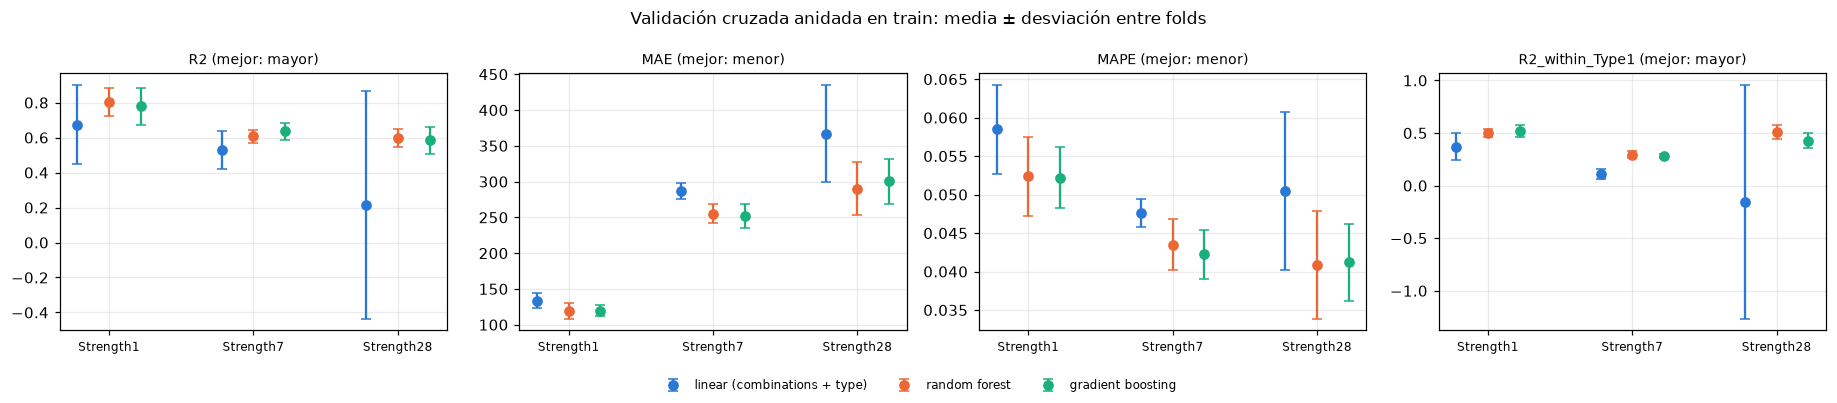

In [25]:
TREE_MODELS = {
    "random forest": lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=0.5,
                                                   random_state=RANDOM_STATE, n_jobs=N_THREADS),
    "gradient boosting": lambda: HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                               min_samples_leaf=10, l2_regularization=1.0,
                                                               random_state=RANDOM_STATE),
}
MODEL_NAMES = [LINEAR] + list(TREE_MODELS)
METRICS = ["R2", "MAE", "MAPE", "R2_within_Type1"]
HIGHER_IS_BETTER = {"R2": True, "MAE": False, "MAPE": False, "R2_within_Type1": True}
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#1baf7a"]))


@dataclass
class Fitted:
    model: object
    cols: list
    build: Callable   # convierte filas en formato Gold a la matriz que espera el modelo

    def predict(self, gold_rows):
        return pd.Series(self.model.predict(self.build(gold_rows)[self.cols]), index=gold_rows.index)


def fit_algo(name, idx, y, cols=None):
    if name == LINEAR:
        cols = cols or select_linear_cols(idx, y)
        return Fitted(make_model().fit(X_all.loc[idx, cols], y), cols, build_model_features)
    return Fitted(TREE_MODELS[name]().fit(X_tree.loc[idx], y), list(X_tree.columns), lambda f: f)


start = time.perf_counter()
fold_rows = []
with threadpool_limits(limits=N_THREADS):
    for target in TARGETS:
        _, ytr, _, _ = get_xy(gold_df, target)
        for fold, (a, b) in enumerate(cv.split(ytr)):
            fit_idx, val_idx = ytr.index[a], ytr.index[b]
            for name in MODEL_NAMES:
                fitted = fit_algo(name, fit_idx, ytr[fit_idx])
                pred = fitted.predict(gold_df.loc[val_idx])
                fold_rows.append({"target": target, "model": name, "fold": fold, **metric_row(ytr[val_idx], pred)})
print(f"Tiempo: {time.perf_counter() - start:.0f} s")

cv_folds = pd.DataFrame(fold_rows)
cv_summary = cv_folds.groupby(["target", "model"], sort=False)[METRICS].agg(["mean", "std"])
cv_summary.columns = [f"cv_{m}_{s}" for m, s in cv_summary.columns]
cv_summary = cv_summary.reset_index()
display(cv_summary.round(3))

fig, axes = plt.subplots(1, len(METRICS), figsize=(4.2 * len(METRICS), 3.6))
offsets = np.linspace(-0.22, 0.22, len(MODEL_NAMES))
for ax, metric in zip(axes, METRICS):
    for off, name in zip(offsets, MODEL_NAMES):
        d = cv_summary[cv_summary["model"] == name].set_index("target").loc[TARGETS]
        ax.errorbar(np.arange(len(TARGETS)) + off, d[f"cv_{metric}_mean"], yerr=d[f"cv_{metric}_std"], fmt="o",
                    markersize=6, linewidth=1.5, capsize=3, color=MODEL_COLORS[name], label=name)
    ax.set_xticks(range(len(TARGETS)), TARGETS, fontsize=8)
    ax.set_title(f"{metric} (mejor: {'mayor' if HIGHER_IS_BETTER[metric] else 'menor'})", fontsize=9)
fig.suptitle("Validación cruzada anidada en train: media ± desviación entre folds", fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(MODEL_NAMES), fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

## 6. Selección del mejor modelo
**Ganador por métrica:** para cada target y cada métrica se lista el mejor modelo en CV.

**Ganador final por target:** lo decide `select_best`. Gana el modelo que obtiene el mejor valor de CV en más métricas, para no depender de una sola. Si hay empate, decide el menor MAE de CV, porque está en las unidades de resistencia con que opera la planta y, a diferencia de `R2` global, no se infla con la diferencia entre tipos de producto.

`select_best` es la decisión que el equipo debe poder defender en el Q&A: cambiarla solo requiere editar esa función.

In [26]:
def winners_by_metric(table, suffix=""):
    """Una fila por target; una columna por métrica con el modelo ganador y su valor."""
    rows = []
    for target in TARGETS:
        d = table[table["target"] == target].set_index("model")
        row = {"target": target}
        for metric in METRICS:
            col = f"{metric}{suffix}"
            best = d[col].idxmax() if HIGHER_IS_BETTER[metric] else d[col].idxmin()
            row[metric] = f"{best} ({d.loc[best, col]:.3f})"
        rows.append(row)
    return pd.DataFrame(rows).set_index("target")


def select_best(cv_table):
    """Elige un modelo por target usando solo métricas de CV en train."""
    picks = {}
    for target, d in cv_table.groupby("target", sort=False):
        d = d.set_index("model")
        wins = pd.Series(0, index=d.index)
        for metric in METRICS:
            col = d[f"cv_{metric}_mean"]
            wins[col.idxmax() if HIGHER_IS_BETTER[metric] else col.idxmin()] += 1
        tied = wins[wins == wins.max()].index
        picks[target] = d.loc[tied, "cv_MAE_mean"].idxmin()
    return picks


print("Mejor modelo por métrica (CV anidada en train)")
display(winners_by_metric(cv_summary.rename(columns={f"cv_{m}_mean": m for m in METRICS})))

best_models = select_best(cv_summary)
print("Ganador final por target:", best_models)

Mejor modelo por métrica (CV anidada en train)


,R2,MAE,MAPE,R2_within_Type1
target,,,,
Strength1,random forest (0.804),random forest (119.154),gradient boosting (0.052),gradient boosting (0.517)
Strength7,gradient boosting (0.636),gradient boosting (252.277),gradient boosting (0.042),random forest (0.295)
Strength28,random forest (0.597),random forest (290.026),random forest (0.041),random forest (0.512)


Ganador final por target: {'Strength1': 'random forest', 'Strength7': 'gradient boosting', 'Strength28': 'random forest'}


### 6.1 Evaluación en test
Cada algoritmo se reentrena con todo el train y se evalúa una sola vez en el test compartido. **Estos resultados no intervienen en la selección.** Sirven para reportar y para ver si la CV y el test coinciden. Con unas 150 filas de test, diferencias pequeñas entre modelos pueden ser ruido.

Tablas comparativas en test: 3 modelos × 3 targets
R2


target,Strength1,Strength7,Strength28
model,,,
linear (combinations + type),0.7180,0.5880,0.5770
random forest,0.7950,0.6590,0.6100
gradient boosting,0.8190,0.6820,0.5990


MAE


target,Strength1,Strength7,Strength28
model,,,
linear (combinations + type),137.1430,272.9060,352.8200
random forest,119.5130,238.8660,309.2910
gradient boosting,113.6630,231.2630,315.8640


MAPE


target,Strength1,Strength7,Strength28
model,,,
linear (combinations + type),0.0620,0.0460,0.0480
random forest,0.0540,0.0410,0.0430
gradient boosting,0.0510,0.0390,0.0430


R2_within_Type1


target,Strength1,Strength7,Strength28
model,,,
linear (combinations + type),0.3070,0.1110,0.3300
random forest,0.5190,0.2870,0.4520
gradient boosting,0.5850,0.3190,0.4260


Mejor modelo por métrica (test, solo como referencia)


,R2,MAE,MAPE,R2_within_Type1
target,,,,
Strength1,gradient boosting (0.819),gradient boosting (113.663),gradient boosting (0.051),gradient boosting (0.585)
Strength7,gradient boosting (0.682),gradient boosting (231.263),gradient boosting (0.039),gradient boosting (0.319)
Strength28,random forest (0.610),random forest (309.291),gradient boosting (0.043),random forest (0.452)


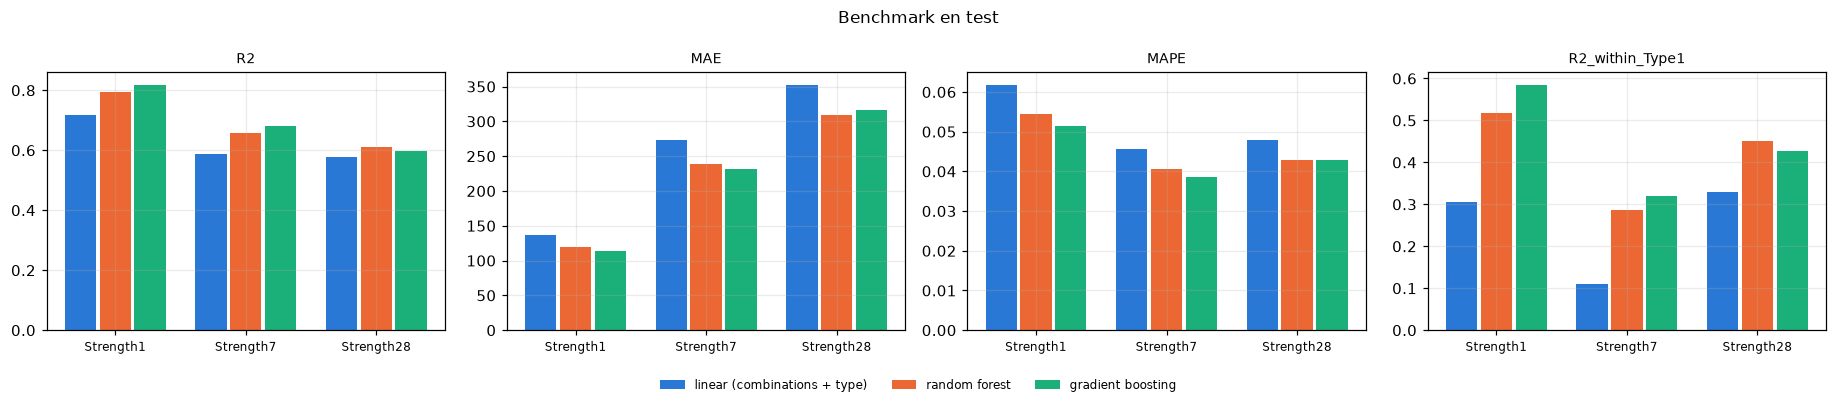

In [27]:
final_fits, holdout_rows = {}, []
with threadpool_limits(limits=N_THREADS):
    for target in TARGETS:
        Xtr, ytr, Xte, yte = get_xy(gold_df, target)
        for name in MODEL_NAMES:
            cols = linear_cols[target] if name == LINEAR else None
            final_fits[target, name] = fit_algo(name, ytr.index, ytr, cols=cols)
            pred = final_fits[target, name].predict(gold_df.loc[yte.index])
            holdout_rows.append({"target": target, "model": name, "n_features": len(final_fits[target, name].cols),
                                 "train_size": len(ytr), "test_size": len(yte), **metric_row(yte, pred)})
holdout = pd.DataFrame(holdout_rows)

print("Tablas comparativas en test: 3 modelos × 3 targets")
for metric in METRICS:
    print(metric)
    display(holdout.pivot(index="model", columns="target", values=metric).loc[MODEL_NAMES, TARGETS].round(3))

print("Mejor modelo por métrica (test, solo como referencia)")
display(winners_by_metric(holdout))

width = 0.8 / len(MODEL_NAMES)
fig, axes = plt.subplots(1, len(METRICS), figsize=(4.2 * len(METRICS), 3.6))
for ax, metric in zip(axes, METRICS):
    for i, name in enumerate(MODEL_NAMES):
        values = holdout[holdout["model"] == name].set_index("target").loc[TARGETS, metric]
        ax.bar(np.arange(len(TARGETS)) + i * width, values, width * 0.9, color=MODEL_COLORS[name], label=name)
    ax.set_xticks(np.arange(len(TARGETS)) + width * (len(MODEL_NAMES) - 1) / 2, TARGETS, fontsize=8)
    ax.set_title(metric, fontsize=9)
fig.suptitle("Benchmark en test", fontsize=11)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=len(MODEL_NAMES), fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### 6.2 Resultado final y predicción
Tabla de ganadores con sus métricas de CV y de test, gráfico real vs. predicho del ganador, y `predict_strengths()`, que recibe datos de calidad crudos y aplica las mismas transformaciones de Silver y Gold con los parámetros aprendidos en train.

✔ guardada datathon.gold.datathon_model_benchmark  (9 filas × 18 cols)
✔ guardada datathon.gold.datathon_best_models  (3 filas × 17 cols)


,target,model,n_features,train_size,test_size,cv_MAE_mean,cv_MAE_std,R2,MAE,MAPE,R2_within_Type1
0,Strength1,random forest,18,589,146,119.1540,10.5200,0.7950,119.5130,0.0540,0.5190
1,Strength7,gradient boosting,18,610,154,252.2770,17.0310,0.6820,231.2630,0.0390,0.3190
2,Strength28,random forest,18,582,147,290.0260,36.9950,0.6100,309.2910,0.0430,0.4520


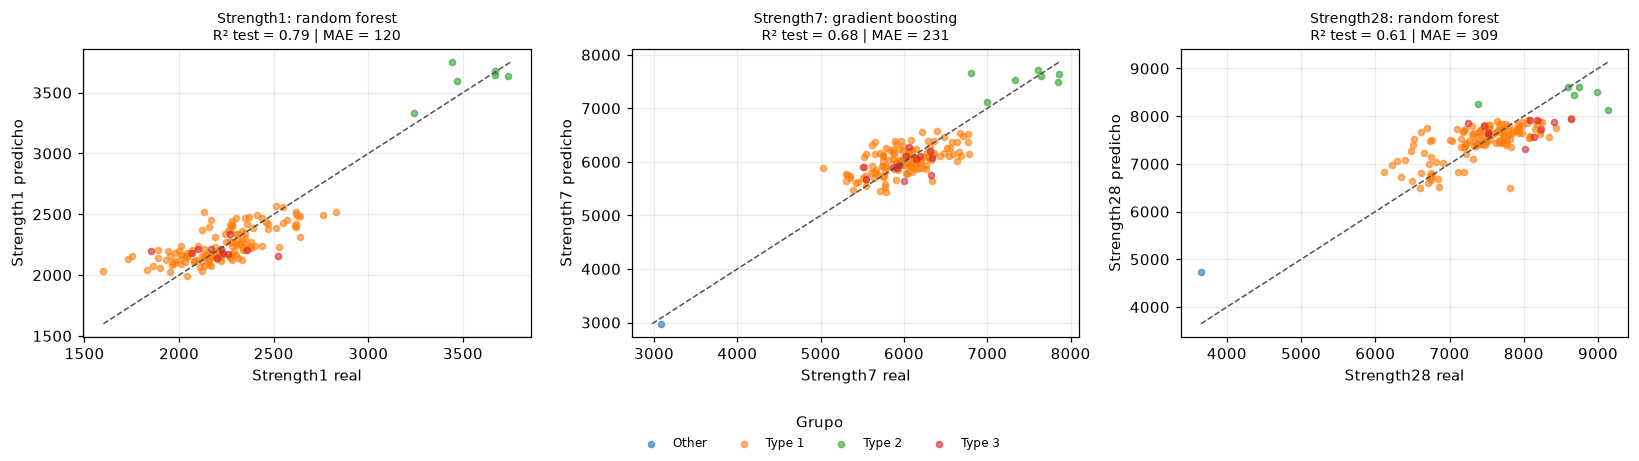

,ProductType,Strength1_pred,Strength7_pred,Strength28_pred,Strength1_real,Strength7_real,Strength28_real
363,Type 1,"2,191.0000","6,054.0000","7,586.0000","2,170.0000","6,000.0000","7,470.0000"
679,Type 1,"2,245.0000","5,962.0000","7,402.0000","2,330.0000","6,040.0000","7,390.0000"
515,Type 1,"2,119.0000","5,738.0000","7,870.0000","2,120.0000","5,660.0000","7,780.0000"
168,Type 1,"2,456.0000","5,698.0000","6,773.0000","2,390.0000","5,740.0000","6,600.0000"
729,Type 3,"2,269.0000","6,464.0000","7,887.0000","2,290.0000","6,480.0000","7,890.0000"


In [28]:
benchmark = holdout.merge(cv_summary, on=["target", "model"])
benchmark["selected"] = [best_models[t] == m for t, m in zip(benchmark["target"], benchmark["model"])]
save_table(benchmark, BENCHMARK)

best_table = benchmark[benchmark["selected"]].drop(columns="selected").reset_index(drop=True)
save_table(best_table, BEST)
display(best_table[["target", "model", "n_features", "train_size", "test_size", "cv_MAE_mean", "cv_MAE_std",
                    "R2", "MAE", "MAPE", "R2_within_Type1"]].round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, target in zip(axes, TARGETS):
    _, _, _, yte = get_xy(gold_df, target)
    pred = final_fits[target, best_models[target]].predict(gold_df.loc[yte.index])
    for group in GROUPS:
        mask = gold_df.loc[yte.index, "ProductType_group"] == group
        if mask.any():
            ax.scatter(yte[mask], pred[mask], alpha=0.6, s=16, color=palette[group], label=group)
    lims = [min(yte.min(), pred.min()), max(yte.max(), pred.max())]
    ax.plot(lims, lims, color="#52514e", linestyle="--", linewidth=1)
    ax.set_xlabel(f"{target} real"); ax.set_ylabel(f"{target} predicho")
    ax.set_title(f"{target}: {best_models[target]}\nR² test = {r2_score(yte, pred):.2f} | MAE = {mean_absolute_error(yte, pred):.0f}", fontsize=9)
# Un panel puede no tener todos los grupos en test: la leyenda reúne los de los tres
legend_items = {label: h for ax in axes for h, label in zip(*ax.get_legend_handles_labels())}
legend_items = {g: legend_items[g] for g in GROUPS if g in legend_items}
fig.legend(legend_items.values(), legend_items.keys(), title="Grupo", loc="lower center", ncol=len(legend_items), fontsize=8, frameon=False)
plt.tight_layout(rect=(0, 0.12, 1, 1)); plt.show()


def prepare_quality_input(samples):
    """Aplica a datos crudos las transformaciones de Silver y Gold con parámetros aprendidos en train."""
    d = samples[[CAT] + FEATURES].apply(lambda s: s if s.name == CAT else pd.to_numeric(s, errors="coerce"))
    product = d[CAT].map(norm_type)
    group = product.where(product.isin(med_group.index), "Other")
    d[FLAGS[0]] = d[PHYS_A].isna().astype(int)
    d[FLAGS[1]] = d[MINERALS].isna().any(axis=1).astype(int)
    for _, r in clip_report[clip_report["recortado"]].iterrows():
        d[r["feature"]] = d[r["feature"]].clip(r["límite_inf"], r["límite_sup"])
    for c in FEAT:
        d[c] = d[c].fillna(group.map(med_group[c])).fillna(med_global[c])
    for c in dummies.columns:
        d[c] = (group.str.replace(" ", "_") == c.removeprefix("ProductType_")).astype(int)
    return d[FEATURE_COLS]


def predict_strengths(samples):
    """Predice Strength1/7/28 con el modelo ganador de cada target. Acepta nulos en las features."""
    X_new = prepare_quality_input(samples)
    return pd.DataFrame({t: final_fits[t, best_models[t]].predict(X_new) for t in TARGETS}, index=samples.index)


# La ruta de predicción debe reproducir Gold exactamente, también en las filas de test
assert np.allclose(prepare_quality_input(silver).to_numpy(float), gold_df[FEATURE_COLS].to_numpy(float))

demo = silver[[CAT] + FEATURES].sample(5, random_state=RANDOM_STATE)
demo_real = silver.loc[demo.index, TARGETS].add_suffix("_real")
display(pd.concat([demo[[CAT]], predict_strengths(demo).add_suffix("_pred").round(0), demo_real], axis=1))

## Siguientes pasos
1. **MLflow:** registrar estos 9 modelos con los params `model_type`, `target`, `n_features`, `train_size` y `test_size`, métricas, `signature`, `input_example`, gráficos e importancia de variables, y registrar los ganadores en el Model Registry.
2. **Dashboard** sobre Gold y las tablas `datathon_model_benchmark` y `datathon_best_models`; `predict_strengths` es la base de la simulación.
3. **Valor de negocio:** traducir el MAE de cada target en aditivos, merma y silos, con supuestos explícitos.